In [10]:
# ============================================================
# Level 2 Pair-Disjoint Reanalysis
# Cell 1 — Environment setup, imports, and reproducibility
# ============================================================

import os
import sys
import json
import random
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import __version__ as sklearn_version
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    log_loss,
    top_k_accuracy_score
)

import joblib
import xgboost as xgb
from xgboost import XGBClassifier

from rdkit import Chem
from rdkit import rdBase
from rdkit.Chem import AllChem
from rdkit.DataStructs import ConvertToNumpyArray


# ------------------------------------------------------------
# Global settings
# ------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE_TARGET = 0.20
N_SPLITS = 5
N_Y_RANDOMIZATION = 20

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 120)

# ------------------------------------------------------------
# Project folders
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

# ملف البيانات موجود مباشرة بجانب الـNotebook
LEVEL2_DATA_FILE = BASE_DIR / "DDI_Level2_filtered_min100.csv"

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
MODELS_DIR = RESULTS_DIR / "models"
SPLITS_DIR = RESULTS_DIR / "splits"
LOGS_DIR = RESULTS_DIR / "logs"

# إنشاء مجلدات النتائج
for folder in [
    RESULTS_DIR,
    FIGURES_DIR,
    TABLES_DIR,
    MODELS_DIR,
    SPLITS_DIR,
    LOGS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Base directory :", BASE_DIR)
print("Dataset path  :", LEVEL2_DATA_FILE)
print("Dataset found :", LEVEL2_DATA_FILE.exists())

# ------------------------------------------------------------
# Expected input file
# Put the Level 2 dataset inside the data folder
# ------------------------------------------------------------

LEVEL2_DATA_FILE = BASE_DIR / "DDI_Level2_filtered_min100.csv"


# ------------------------------------------------------------
# Helper function for reproducibility information
# ------------------------------------------------------------

def print_environment_info():
    print("=" * 70)
    print("LEVEL 2 PAIR-DISJOINT REANALYSIS")
    print("=" * 70)
    print(f"Run date        : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"Python          : {sys.version.split()[0]}")
    print(f"NumPy           : {np.__version__}")
    print(f"Pandas          : {pd.__version__}")
    print(f"Scikit-learn    : {sklearn_version}")
    print(f"XGBoost         : {xgb.__version__}")
    print(f"RDKit           : {rdBase.rdkitVersion}")
    print(f"Random state    : {RANDOM_STATE}")
    print(f"Target test size: {TEST_SIZE_TARGET:.0%}")
    print(f"Group folds     : {N_SPLITS}")
    print(f"Y-randomization : {N_Y_RANDOMIZATION} runs")
    print("-" * 70)
    print(f"Base directory  : {BASE_DIR}")
    print(f"Input dataset   : {LEVEL2_DATA_FILE}")
    print(f"Results folder  : {RESULTS_DIR}")
    print("=" * 70)


print_environment_info()


# ------------------------------------------------------------
# Initial input-file check
# ------------------------------------------------------------

if LEVEL2_DATA_FILE.exists():
    print("\n✓ Level 2 dataset found.")
else:
    print(
        "\n⚠ Dataset not found.\n"
        f"Place the file here:\n{LEVEL2_DATA_FILE}\n"
        "or modify LEVEL2_DATA_FILE to its actual location."
    )

Base directory : C:\Users\user\Desktop\drug drug\drug2
Dataset path  : C:\Users\user\Desktop\drug drug\drug2\DDI_Level2_filtered_min100.csv
Dataset found : True
LEVEL 2 PAIR-DISJOINT REANALYSIS
Run date        : 2026-08-01 19:51:39
Python          : 3.10.19
NumPy           : 2.2.6
Pandas          : 2.3.3
Scikit-learn    : 1.7.2
XGBoost         : 3.2.0
RDKit           : 2025.09.4
Random state    : 42
Target test size: 20%
Group folds     : 5
Y-randomization : 20 runs
----------------------------------------------------------------------
Base directory  : C:\Users\user\Desktop\drug drug\drug2
Input dataset   : C:\Users\user\Desktop\drug drug\drug2\DDI_Level2_filtered_min100.csv
Results folder  : C:\Users\user\Desktop\drug drug\drug2\results_level2_pair_disjoint

✓ Level 2 dataset found.


In [11]:
# ============================================================
# Cell 2 — Load Level 2 dataset and inspect its structure
# ============================================================

# Load dataset
df = pd.read_csv(LEVEL2_DATA_FILE)

print("=" * 70)
print("LEVEL 2 DATASET LOADED")
print("=" * 70)

print(f"Dataset shape : {df.shape}")
print(f"Rows          : {df.shape[0]:,}")
print(f"Columns       : {df.shape[1]:,}")

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing_table = (
    df.isna()
      .sum()
      .to_frame("Missing_Count")
      .assign(Missing_Percent=lambda x: 100 * x["Missing_Count"] / len(df))
      .sort_values("Missing_Count", ascending=False)
)

display(missing_table.head(20))

print("\nDuplicated complete rows:")
print(df.duplicated().sum())

print("=" * 70)

LEVEL 2 DATASET LOADED
Dataset shape : (220434, 7)
Rows          : 220,434
Columns       : 7

Column names:
01. Drug1
02. Drug2
03. Interaction_ID
04. SMILES1
05. SMILES2
06. Level1
07. Level1_binary

First 5 rows:


,Drug1,Drug2,Interaction_ID,SMILES1,SMILES2,Level1,Level1_binary
0,DB13231,DB00808,2,[Ca++].CC(O)C([O-])=O.CC(O)C([O-])=O,CC1CC2=CC=CC=C2N1NC(=O)C1=CC(=C(Cl)C=C1)S(N)(=O)=O,2,0
1,DB00684,DB00533,2,NC[C@H]1O[C@H](O[C@@H]2[C@@H](N)C[C@@H](N)[C@H](O[C@H]3O[C@H](CO)[C@@H](O)[C@H](N)[C@H]3O)[C@H]2O)[C@H](N)C[C@@H]1O,CS(=O)(=O)C1=CC=C(C=C1)C1=C(C(=O)OC1)C1=CC=CC=C1,2,0
2,DB00865,DB13209,2,C[C@@H](CC1=CC=CC=C1)N(C)CC1=CC=CC=C1,[OH-].[OH-].[OH-].[OH-].[OH-].[OH-].[OH-].[OH-].[OH-].[O--].[Bi+3].[Bi+3].[Bi+3].[Bi+3].[Bi+3].[O-][N+]([O-])=O.[O-]...,2,0
3,DB00955,DB00768,2,CCN[C@@H]1C[C@H](N)[C@@H](O[C@H]2OC(CN)=CC[C@H]2N)[C@H](O)[C@H]1O[C@H]1OC[C@](C)(O)[C@H](NC)[C@H]1O,CN(C)CC\C=C1\C2=CC=CC=C2COC2=C1C=C(CC(O)=O)C=C2,2,0
4,DB01082,DB09216,2,CN[C@H]1[C@H](O)[C@@H](O)[C@H](CO)O[C@H]1O[C@H]1[C@H](O[C@H]2[C@H](O)[C@@H](O)[C@H](NC(N)=N)[C@@H](O)[C@@H]2NC(N)=N)...,CC1=C(Cl)C=CC=C1NC1=CC=CC=C1C(O)=O,2,0



Data types:


,dtype
Drug1,object
Drug2,object
Interaction_ID,int64
SMILES1,object
SMILES2,object
Level1,int64
Level1_binary,int64



Missing values:


,Missing_Count,Missing_Percent
Drug1,0,0.0
Drug2,0,0.0
Interaction_ID,0,0.0
SMILES1,0,0.0
SMILES2,0,0.0
Level1,0,0.0
Level1_binary,0,0.0



Duplicated complete rows:
0


In [12]:
# ============================================================
# Cell 3 — Create canonical drug pairs and audit the dataset
# ============================================================

print("=" * 70)
print("CREATING CANONICAL DRUG PAIRS")
print("=" * 70)

# ------------------------------------------------------------
# Canonical pair
# (A,B) == (B,A)
# ------------------------------------------------------------

df["Pair_ID"] = df.apply(
    lambda r: "__".join(sorted([str(r["Drug1"]), str(r["Drug2"])])),
    axis=1
)

# ------------------------------------------------------------
# Basic statistics
# ------------------------------------------------------------

n_rows = len(df)
n_unique_pairs = df["Pair_ID"].nunique()

print(f"Total interaction rows : {n_rows:,}")
print(f"Unique canonical pairs : {n_unique_pairs:,}")
print(f"Average rows per pair  : {n_rows/n_unique_pairs:.3f}")

# ------------------------------------------------------------
# Multiple interaction types per pair
# ------------------------------------------------------------

pair_summary = (
    df.groupby("Pair_ID")
      .agg(
          n_rows=("Interaction_ID","size"),
          n_classes=("Interaction_ID","nunique"),
          n_level1=("Level1","nunique")
      )
      .reset_index()
)

multi_class_pairs = pair_summary[pair_summary["n_classes"] > 1]
multi_level1_pairs = pair_summary[pair_summary["n_level1"] > 1]

print("\nPairs with multiple Interaction_ID labels :",
      len(multi_class_pairs))

print("Pairs with multiple Level1 labels         :",
      len(multi_level1_pairs))

# ------------------------------------------------------------
# Show examples
# ------------------------------------------------------------

if len(multi_class_pairs):

    print("\nExample pairs with multiple Interaction_ID:\n")

    example = multi_class_pairs.head(10)["Pair_ID"]

    display(
        df[df["Pair_ID"].isin(example)]
        .sort_values(["Pair_ID","Interaction_ID"])
    )

if len(multi_level1_pairs):

    print("\nWARNING: pairs belonging to multiple Level1 classes\n")

    example = multi_level1_pairs.head(10)["Pair_ID"]

    display(
        df[df["Pair_ID"].isin(example)]
        .sort_values(["Pair_ID","Level1"])
    )

print("=" * 70)

CREATING CANONICAL DRUG PAIRS
Total interaction rows : 220,434
Unique canonical pairs : 219,941
Average rows per pair  : 1.002

Pairs with multiple Interaction_ID labels : 423
Pairs with multiple Level1 labels         : 60

Example pairs with multiple Interaction_ID:



,Drug1,Drug2,Interaction_ID,SMILES1,SMILES2,Level1,Level1_binary,Pair_ID
47865,DB00091,DB00541,20,CC[C@@H]1NC(=O)[C@H]([C@H](O)[C@H](C)C\C=C\C)N(C)C(=O)[C@H](C(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(...,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,2,0,DB00091__DB00541
113744,DB00541,DB00091,89,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,CC[C@@H]1NC(=O)[C@H]([C@H](O)[C@H](C)C\C=C\C)N(C)C(=O)[C@H](C(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(...,2,0,DB00091__DB00541
27574,DB00997,DB00091,3,COC1=CC=CC2=C1C(=O)C1=C(O)C3=C(C[C@](O)(C[C@@H]3O[C@H]3C[C@H](N)[C@H](O)[C@H](C)O3)C(=O)CO)C(O)=C1C2=O,CC[C@@H]1NC(=O)[C@H]([C@H](O)[C@H](C)C\C=C\C)N(C)C(=O)[C@H](C(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(...,2,0,DB00091__DB00997
147831,DB00997,DB00091,89,COC1=CC=CC2=C1C(=O)C1=C(O)C3=C(C[C@](O)(C[C@@H]3O[C@H]3C[C@H](N)[C@H](O)[C@H](C)O3)C(=O)CO)C(O)=C1C2=O,CC[C@@H]1NC(=O)[C@H]([C@H](O)[C@H](C)C\C=C\C)N(C)C(=O)[C@H](C(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(...,2,0,DB00091__DB00997
26108,DB09027,DB00091,3,COC(=O)N[C@@H](C(C)C)C(=O)N1CC2(CC2)C[C@H]1C1=NC(=CN1)C1=CC=C2C3=CC=C(C=C3C(F)(F)C2=C1)C1=CC=C2NC(=NC2=C1)[C@@H]1[C@...,CC[C@@H]1NC(=O)[C@H]([C@H](O)[C@H](C)C\C=C\C)N(C)C(=O)[C@H](C(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(...,2,0,DB00091__DB09027
36383,DB00091,DB09027,20,CC[C@@H]1NC(=O)[C@H]([C@H](O)[C@H](C)C\C=C\C)N(C)C(=O)[C@H](C(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(=O)[C@H](CC(C)C)N(C)C(...,COC(=O)N[C@@H](C(C)C)C(=O)N1CC2(CC2)C[C@H]1C1=NC(=CN1)C1=CC=C2C3=CC=C(C=C3C(F)(F)C2=C1)C1=CC=C2NC(=NC2=C1)[C@@H]1[C@...,2,0,DB00091__DB09027
2030,DB00997,DB00169,3,COC1=CC=CC2=C1C(=O)C1=C(O)C3=C(C[C@](O)(C[C@@H]3O[C@H]3C[C@H](N)[C@H](O)[C@H](C)O3)C(=O)CO)C(O)=C1C2=O,CC(C)CCC[C@@H](C)[C@@]1([H])CC[C@@]2([H])\C(CCC[C@]12C)=C\C=C1\C[C@@H](O)CCC1=C,2,0,DB00169__DB00997
112981,DB00997,DB00169,89,COC1=CC=CC2=C1C(=O)C1=C(O)C3=C(C[C@](O)(C[C@@H]3O[C@H]3C[C@H](N)[C@H](O)[C@H](C)O3)C(=O)CO)C(O)=C1C2=O,CC(C)CCC[C@@H](C)[C@@]1([H])CC[C@@]2([H])\C(CCC[C@]12C)=C\C=C1\C[C@@H](O)CCC1=C,2,0,DB00169__DB00997
23892,DB00175,DB00541,3,[H][C@]12[C@H](C[C@H](O)C=C1C=C[C@H](C)[C@@H]2CC[C@@H](O)C[C@@H](O)CC(O)=O)OC(=O)[C@@H](C)CC,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,2,0,DB00175__DB00541
35728,DB00541,DB00175,17,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,[H][C@]12[C@H](C[C@H](O)C=C1C=C[C@H](C)[C@@H]2CC[C@@H](O)C[C@@H](O)CC(O)=O)OC(=O)[C@@H](C)CC,2,0,DB00175__DB00541


,Drug1,Drug2,Interaction_ID,SMILES1,SMILES2,Level1,Level1_binary,Pair_ID
141417,DB00182,DB01156,89,CC(N)CC1=CC=CC=C1,CC(NC(C)(C)C)C(=O)C1=CC(Cl)=CC=C1,2,0,DB00182__DB01156
197169,DB00182,DB01156,113,CC(N)CC1=CC=CC=C1,CC(NC(C)(C)C)C(=O)C1=CC(Cl)=CC=C1,3,1,DB00182__DB01156
63408,DB00246,DB01233,53,ClC1=C(CCN2CCN(CC2)C2=NSC3=CC=CC=C23)C=C2CC(=O)NC2=C1,CCN(CC)CCNC(=O)C1=CC(Cl)=C(N)C=C1OC,2,0,DB00246__DB01233
189608,DB01233,DB00246,113,CCN(CC)CCNC(=O)C1=CC(Cl)=C(N)C=C1OC,ClC1=C(CCN2CCN(CC2)C2=NSC3=CC=CC=C23)C=C2CC(=O)NC2=C1,3,1,DB00246__DB01233
35731,DB00541,DB00305,17,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,[H][C@]12CN3C4=C([C@@H](COC(N)=O)[C@@]3(OC)[C@@]1([H])N2)C(=O)C(N)=C(C)C4=O,2,0,DB00305__DB00541
172180,DB00541,DB00305,113,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,[H][C@]12CN3C4=C([C@@H](COC(N)=O)[C@@]3(OC)[C@@]1([H])N2)C(=O)C(N)=C(C)C4=O,3,1,DB00305__DB00541
8002,DB00307,DB01229,3,CC1=CC2=C(C=C1C(=C)C1=CC=C(C=C1)C(O)=O)C(C)(C)CCC2(C)C,[H][C@]12[C@H](OC(=O)C3=CC=CC=C3)[C@]3(O)C[C@H](OC(=O)[C@H](O)[C@@H](NC(=O)C4=CC=CC=C4)C4=CC=CC=C4)C(C)=C([C@@H](OC(...,2,0,DB00307__DB01229
212251,DB01229,DB00307,113,[H][C@]12[C@H](OC(=O)C3=CC=CC=C3)[C@]3(O)C[C@H](OC(=O)[C@H](O)[C@@H](NC(=O)C4=CC=CC=C4)C4=CC=CC=C4)C(C)=C([C@@H](OC(...,CC1=CC2=C(C=C1C(=C)C1=CC=C(C=C1)C(O)=O)C(C)(C)CCC2(C)C,3,1,DB00307__DB01229
35604,DB00541,DB00320,17,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,[H][C@@]12CCCN1C(=O)[C@H](CC1=CC=CC=C1)N1C(=O)[C@](C)(NC(=O)[C@H]3CN(C)[C@]4([H])CC5=CNC6=CC=CC(=C56)[C@@]4([H])C3)O...,2,0,DB00320__DB00541
211255,DB00320,DB00541,113,[H][C@@]12CCCN1C(=O)[C@H](CC1=CC=CC=C1)N1C(=O)[C@](C)(NC(=O)[C@H]3CN(C)[C@]4([H])CC5=CNC6=CC=CC(=C56)[C@@]4([H])C3)O...,[H][C@@]12N3CC[C@@]11C4=C(C=C(OC)C(=C4)[C@]4(C[C@H]5C[N@](C[C@](O)(CC)C5)CCC5=C4NC4=CC=CC=C54)C(=O)OC)N(C=O)[C@@]1([...,3,1,DB00320__DB00541


In [13]:
# ============================================================
# Cell 4 — Audit duplicated pairs in detail
# ============================================================

pair_details = (
    df.groupby("Pair_ID")
      .agg(
          Drug1=("Drug1", "first"),
          Drug2=("Drug2", "first"),
          Rows=("Interaction_ID", "size"),
          Unique_Interactions=("Interaction_ID", "nunique"),
          Interaction_List=("Interaction_ID", lambda x: sorted(set(x))),
          Unique_Level1=("Level1", "nunique"),
          Level1_List=("Level1", lambda x: sorted(set(x)))
      )
      .reset_index()
)

# الأزواج التي لها أكثر من Interaction_ID
multi_interaction = pair_details[
    pair_details["Unique_Interactions"] > 1
].copy()

# الأزواج التي لها أكثر من Level1
multi_level1 = pair_details[
    pair_details["Unique_Level1"] > 1
].copy()

print("="*70)
print(f"Pairs with >1 Interaction_ID : {len(multi_interaction):,}")
print(f"Pairs with >1 Level1         : {len(multi_level1):,}")
print("="*70)

display(multi_interaction.head(20))
display(multi_level1.head(20))

# حفظ التقرير
multi_interaction.to_csv(
    RESULTS_DIR / "Pairs_multiple_interactions.csv",
    index=False
)

multi_level1.to_csv(
    RESULTS_DIR / "Pairs_multiple_level1.csv",
    index=False
)

Pairs with >1 Interaction_ID : 423
Pairs with >1 Level1         : 60


,Pair_ID,Drug1,Drug2,Rows,Unique_Interactions,Interaction_List,Unique_Level1,Level1_List
754,DB00091__DB00541,DB00091,DB00541,2,2,"[20, 89]",1,[2]
948,DB00091__DB00997,DB00997,DB00091,2,2,"[3, 89]",1,[2]
1290,DB00091__DB09027,DB09027,DB00091,2,2,"[3, 20]",1,[2]
2644,DB00169__DB00997,DB00997,DB00169,2,2,"[3, 89]",1,[2]
2992,DB00175__DB00541,DB00175,DB00541,2,2,"[3, 17]",1,[2]
3671,DB00176__DB00997,DB00997,DB00176,2,2,"[3, 89]",1,[2]
6214,DB00182__DB01156,DB00182,DB01156,2,2,"[89, 113]",2,"[2, 3]"
6722,DB00184__DB09256,DB00184,DB09256,2,2,"[33, 89]",1,[2]
7983,DB00188__DB00997,DB00997,DB00188,2,2,"[3, 89]",1,[2]
9733,DB00195__DB00997,DB00997,DB00195,2,2,"[3, 89]",1,[2]


,Pair_ID,Drug1,Drug2,Rows,Unique_Interactions,Interaction_List,Unique_Level1,Level1_List
6214,DB00182__DB01156,DB00182,DB01156,2,2,"[89, 113]",2,"[2, 3]"
26220,DB00246__DB01233,DB00246,DB01233,2,2,"[53, 113]",2,"[2, 3]"
42136,DB00305__DB00541,DB00541,DB00305,2,2,"[17, 113]",2,"[2, 3]"
42230,DB00307__DB01229,DB00307,DB01229,2,2,"[3, 113]",2,"[2, 3]"
45584,DB00320__DB00541,DB00541,DB00320,2,2,"[17, 113]",2,"[2, 3]"
45774,DB00320__DB00997,DB00997,DB00320,2,2,"[3, 113]",2,"[2, 3]"
56525,DB00363__DB00997,DB00997,DB00363,2,2,"[3, 113]",2,"[2, 3]"
56643,DB00363__DB01233,DB01233,DB00363,2,2,"[89, 113]",2,"[2, 3]"
67450,DB00420__DB01233,DB01233,DB00420,2,2,"[89, 113]",2,"[2, 3]"
79369,DB00477__DB01233,DB01233,DB00477,2,2,"[89, 113]",2,"[2, 3]"


In [14]:
# ============================================================
# Cell 4 — Create a pair-disjoint train/test split for Level 2
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold

# ------------------------------------------------------------
# Required columns
# ------------------------------------------------------------

LABEL_COL = "Interaction_ID"
GROUP_COL = "Pair_ID"

# Ensure canonical pair ID exists
if GROUP_COL not in df.columns:
    df[GROUP_COL] = df.apply(
        lambda r: "__".join(
            sorted([str(r["Drug1"]).strip(), str(r["Drug2"]).strip()])
        ),
        axis=1
    )

# ------------------------------------------------------------
# Prepare arrays
# ------------------------------------------------------------

X_dummy = np.zeros((len(df), 1))
y_split = df[LABEL_COL].astype(str).values
groups = df[GROUP_COL].astype(str).values

# Five group-aware folds:
# each fold is approximately a 20% test set
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

candidate_splits = []

for fold_id, (train_idx, test_idx) in enumerate(
    sgkf.split(X_dummy, y_split, groups),
    start=1
):
    train_df_candidate = df.iloc[train_idx]
    test_df_candidate = df.iloc[test_idx]

    train_pairs = set(train_df_candidate[GROUP_COL])
    test_pairs = set(test_df_candidate[GROUP_COL])
    shared_pairs = train_pairs.intersection(test_pairs)

    test_fraction = len(test_idx) / len(df)

    # Compare class proportions between full data and test fold
    full_dist = (
        df[LABEL_COL]
        .value_counts(normalize=True)
        .sort_index()
    )

    test_dist = (
        test_df_candidate[LABEL_COL]
        .value_counts(normalize=True)
        .reindex(full_dist.index, fill_value=0)
        .sort_index()
    )

    distribution_error = np.abs(full_dist - test_dist).mean()

    candidate_splits.append({
        "fold": fold_id,
        "train_idx": train_idx,
        "test_idx": test_idx,
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "test_fraction": test_fraction,
        "shared_pairs": len(shared_pairs),
        "distribution_error": distribution_error
    })

# ------------------------------------------------------------
# Compare the five candidate folds
# ------------------------------------------------------------

split_comparison = pd.DataFrame([
    {
        "Fold": s["fold"],
        "Train_rows": s["train_rows"],
        "Test_rows": s["test_rows"],
        "Test_fraction": s["test_fraction"],
        "Shared_pairs": s["shared_pairs"],
        "Mean_class_distribution_error": s["distribution_error"]
    }
    for s in candidate_splits
])

display(split_comparison)

# ------------------------------------------------------------
# Select the fold closest to 20% with best class distribution
# ------------------------------------------------------------

valid_splits = [
    s for s in candidate_splits
    if s["shared_pairs"] == 0
]

if not valid_splits:
    raise RuntimeError(
        "No leakage-free split was produced."
    )

best_split = min(
    valid_splits,
    key=lambda s: (
        abs(s["test_fraction"] - TEST_SIZE_TARGET),
        s["distribution_error"]
    )
)

train_idx = best_split["train_idx"]
test_idx = best_split["test_idx"]

level2_train = df.iloc[train_idx].copy().reset_index(drop=True)
level2_test = df.iloc[test_idx].copy().reset_index(drop=True)

# ------------------------------------------------------------
# Final leakage verification
# ------------------------------------------------------------

train_pairs = set(level2_train[GROUP_COL])
test_pairs = set(level2_test[GROUP_COL])
shared_pairs = train_pairs.intersection(test_pairs)

print("=" * 70)
print("SELECTED PAIR-DISJOINT SPLIT")
print("=" * 70)
print(f"Selected fold            : {best_split['fold']}")
print(f"Training rows            : {len(level2_train):,}")
print(f"Test rows                : {len(level2_test):,}")
print(f"Training canonical pairs : {level2_train[GROUP_COL].nunique():,}")
print(f"Test canonical pairs     : {level2_test[GROUP_COL].nunique():,}")
print(f"Test fraction            : {len(level2_test) / len(df):.4f}")
print(f"Shared canonical pairs   : {len(shared_pairs)}")
print("=" * 70)

assert len(shared_pairs) == 0, "Pair leakage detected."

# ------------------------------------------------------------
# Save the new split
# ------------------------------------------------------------

level2_train.to_csv(
    SPLITS_DIR / "Level2_Train_Pair_Disjoint.csv",
    index=False
)

level2_test.to_csv(
    SPLITS_DIR / "Level2_Test_Pair_Disjoint.csv",
    index=False
)

split_comparison.to_csv(
    TABLES_DIR / "Pair_Disjoint_Fold_Comparison.csv",
    index=False
)

print("\n✓ Pair-disjoint split saved successfully.")

,Fold,Train_rows,Test_rows,Test_fraction,Shared_pairs,Mean_class_distribution_error
0,1,176347,44087,0.200001,0,0.000269
1,2,176343,44091,0.200019,0,0.000228
2,3,176358,44076,0.199951,0,0.000275
3,4,176348,44086,0.199996,0,0.000195
4,5,176340,44094,0.200033,0,0.000152


SELECTED PAIR-DISJOINT SPLIT
Selected fold            : 1
Training rows            : 176,347
Test rows                : 44,087
Training canonical pairs : 175,953
Test canonical pairs     : 43,988
Test fraction            : 0.2000
Shared canonical pairs   : 0

✓ Pair-disjoint split saved successfully.


In [15]:
# ============================================================
# Cell 5 — Generate Morgan fingerprints for the new split
# ============================================================

from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from tqdm.auto import tqdm

# ------------------------------------------------------------
# Fingerprint parameters — keep identical to original Level 2
# ------------------------------------------------------------

MORGAN_RADIUS = 2
MORGAN_BITS = 2048
PAIR_FEATURES = MORGAN_BITS * 2

print("=" * 70)
print("MORGAN FINGERPRINT GENERATION")
print("=" * 70)
print(f"Radius                : {MORGAN_RADIUS}")
print(f"Bits per drug         : {MORGAN_BITS}")
print(f"Features per drug pair: {PAIR_FEATURES}")
print("=" * 70)


# ------------------------------------------------------------
# Convert one SMILES into a NumPy Morgan fingerprint
# ------------------------------------------------------------

def smiles_to_morgan(smiles, radius=MORGAN_RADIUS, n_bits=MORGAN_BITS):
    """
    Convert a SMILES string to a Morgan fingerprint NumPy array.
    Returns None if the SMILES cannot be parsed.
    """
    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
        return None

    fp = AllChem.GetMorganFingerprintAsBitVect(
        mol,
        radius=radius,
        nBits=n_bits
    )

    arr = np.zeros((n_bits,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)

    return arr


# ------------------------------------------------------------
# Cache fingerprints by drug ID
# This avoids calculating the same drug fingerprint repeatedly
# ------------------------------------------------------------

def build_drug_fingerprint_cache(train_df, test_df):
    drug_smiles = pd.concat(
        [
            train_df[["Drug1", "SMILES1"]]
                .rename(columns={"Drug1": "Drug", "SMILES1": "SMILES"}),

            train_df[["Drug2", "SMILES2"]]
                .rename(columns={"Drug2": "Drug", "SMILES2": "SMILES"}),

            test_df[["Drug1", "SMILES1"]]
                .rename(columns={"Drug1": "Drug", "SMILES1": "SMILES"}),

            test_df[["Drug2", "SMILES2"]]
                .rename(columns={"Drug2": "Drug", "SMILES2": "SMILES"})
        ],
        ignore_index=True
    )

    drug_smiles["Drug"] = drug_smiles["Drug"].astype(str).str.strip()
    drug_smiles["SMILES"] = drug_smiles["SMILES"].astype(str).str.strip()

    # Keep one SMILES per DrugBank ID
    drug_smiles = drug_smiles.drop_duplicates(
        subset=["Drug"],
        keep="first"
    )

    cache = {}
    invalid_drugs = []

    for row in tqdm(
        drug_smiles.itertuples(index=False),
        total=len(drug_smiles),
        desc="Calculating unique drug fingerprints"
    ):
        fp = smiles_to_morgan(row.SMILES)

        if fp is None:
            invalid_drugs.append({
                "Drug": row.Drug,
                "SMILES": row.SMILES
            })
        else:
            cache[row.Drug] = fp

    return cache, pd.DataFrame(invalid_drugs)


drug_fp_cache, invalid_drugs_df = build_drug_fingerprint_cache(
    level2_train,
    level2_test
)

print(f"\nUnique valid drug fingerprints: {len(drug_fp_cache):,}")
print(f"Invalid drug SMILES           : {len(invalid_drugs_df):,}")

if len(invalid_drugs_df) > 0:
    display(invalid_drugs_df.head(20))

    invalid_drugs_df.to_csv(
        TABLES_DIR / "Invalid_SMILES_Level2.csv",
        index=False
    )


# ------------------------------------------------------------
# Construct pair features: Drug1 FP + Drug2 FP
# ------------------------------------------------------------

def build_pair_feature_matrix(dataframe, fingerprint_cache):
    features = []
    valid_indices = []
    failed_rows = []

    for idx, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe),
        desc="Building pair feature matrix"
    ):
        drug1 = str(row["Drug1"]).strip()
        drug2 = str(row["Drug2"]).strip()

        fp1 = fingerprint_cache.get(drug1)
        fp2 = fingerprint_cache.get(drug2)

        if fp1 is None or fp2 is None:
            failed_rows.append({
                "Row_Index": idx,
                "Drug1": drug1,
                "Drug2": drug2,
                "Drug1_FP_Available": fp1 is not None,
                "Drug2_FP_Available": fp2 is not None
            })
            continue

        pair_fp = np.concatenate([fp1, fp2])

        features.append(pair_fp)
        valid_indices.append(idx)

    if len(features) == 0:
        raise RuntimeError("No valid pair fingerprints were generated.")

    X = np.asarray(features, dtype=np.uint8)

    filtered_df = (
        dataframe.loc[valid_indices]
        .copy()
        .reset_index(drop=True)
    )

    failed_df = pd.DataFrame(failed_rows)

    return X, filtered_df, failed_df


X_train, level2_train_valid, failed_train = build_pair_feature_matrix(
    level2_train,
    drug_fp_cache
)

X_test, level2_test_valid, failed_test = build_pair_feature_matrix(
    level2_test,
    drug_fp_cache
)


# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE MATRICES CREATED")
print("=" * 70)
print(f"X_train shape       : {X_train.shape}")
print(f"X_test shape        : {X_test.shape}")
print(f"Valid training rows : {len(level2_train_valid):,}")
print(f"Valid test rows     : {len(level2_test_valid):,}")
print(f"Failed train rows   : {len(failed_train):,}")
print(f"Failed test rows    : {len(failed_test):,}")
print(f"Feature data type   : {X_train.dtype}")
print("=" * 70)

assert X_train.shape[1] == 4096
assert X_test.shape[1] == 4096
assert X_train.shape[0] == len(level2_train_valid)
assert X_test.shape[0] == len(level2_test_valid)

if len(failed_train) > 0:
    failed_train.to_csv(
        TABLES_DIR / "Failed_Train_Pair_Features.csv",
        index=False
    )

if len(failed_test) > 0:
    failed_test.to_csv(
        TABLES_DIR / "Failed_Test_Pair_Features.csv",
        index=False
    )

print("\n✓ Morgan pair features generated successfully.")

MORGAN FINGERPRINT GENERATION
Radius                : 2
Bits per drug         : 2048
Features per drug pair: 4096


Calculating unique drug fingerprints:   0%|          | 0/1845 [00:00<?, ?it/s]

[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerat


Unique valid drug fingerprints: 1,844
Invalid drug SMILES           : 1


[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerator
[19:53:09] DEPRECATION WARNING: please use MorganGenerat

,Drug,SMILES
0,DB11630,OC1=CC=CC(=C1)C-1=C2\CCC(=N2)\C(=C2/N\C(\C=C2)=C(/C2=N/C(/C=C2)=C(\C2=CC=C\-1N2)C1=CC(O)=CC=C1)C1=CC(O)=CC=C1)\C1=CC...


Building pair feature matrix:   0%|          | 0/176347 [00:00<?, ?it/s]

Building pair feature matrix:   0%|          | 0/44087 [00:00<?, ?it/s]


FEATURE MATRICES CREATED
X_train shape       : (176339, 4096)
X_test shape        : (44086, 4096)
Valid training rows : 176,339
Valid test rows     : 44,086
Failed train rows   : 8
Failed test rows    : 1
Feature data type   : uint8

✓ Morgan pair features generated successfully.


In [16]:
from sklearn.preprocessing import LabelEncoder

le_level2 = LabelEncoder()

y_train = le_level2.fit_transform(
    level2_train_valid["Interaction_ID"]
)

y_test = le_level2.transform(
    level2_test_valid["Interaction_ID"]
)

print("Number of classes :", len(le_level2.classes_))
print("Training samples  :", len(y_train))
print("Test samples      :", len(y_test))

Number of classes : 61
Training samples  : 176339
Test samples      : 44086


In [17]:
from xgboost import XGBClassifier

level2_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(le_level2.classes_),
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

level2_model.fit(X_train, y_train)

print("✓ Level 2 model trained successfully.")

✓ Level 2 model trained successfully.


In [18]:
import joblib

# Save model
joblib.dump(
    level2_model,
    MODELS_DIR / "Level2_XGB_PairDisjoint.pkl"
)

# Save label encoder
joblib.dump(
    le_level2,
    MODELS_DIR / "Level2_LabelEncoder.pkl"
)

print("✓ Model and LabelEncoder saved.")

✓ Model and LabelEncoder saved.


In [19]:
level2_train_valid.to_csv(
    SPLITS_DIR / "Level2_Train_PairDisjoint.csv",
    index=False
)

level2_test_valid.to_csv(
    SPLITS_DIR / "Level2_Test_PairDisjoint.csv",
    index=False
)

print("✓ Train/Test saved.")

✓ Train/Test saved.


In [21]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score
)
import pandas as pd

# Predictions
y_pred = level2_model.predict(X_test)
y_prob = level2_model.predict_proba(X_test)

# Metrics
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Macro Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "MCC": matthews_corrcoef(y_test, y_pred),
    "Top-3 Accuracy": top_k_accuracy_score(
        y_test,
        y_prob,
        k=3,
        labels=range(len(le_level2.classes_))
    )
}

results_df = pd.DataFrame(results, index=["Level2_PairDisjoint"]).T

display(results_df)

cm = confusion_matrix(y_test, y_pred)

print(classification_report(y_test, y_pred, zero_division=0))

,Level2_PairDisjoint
Accuracy,0.871161
Balanced Accuracy,0.908721
Macro Precision,0.918064
Macro Recall,0.908721
Macro F1,0.911494
Weighted F1,0.870007
MCC,0.850710
Top-3 Accuracy,0.986753


              precision    recall  f1-score   support

           0       0.98      0.97      0.98       260
           1       0.90      0.74      0.81      5477
           2       0.94      0.98      0.96       148
           3       0.81      0.77      0.79       108
           4       0.93      0.93      0.93       603
           5       0.95      1.00      0.97       222
           6       0.89      0.90      0.90        71
           7       0.98      0.97      0.98       349
           8       0.97      0.97      0.97        32
           9       0.93      0.98      0.95       137
          10       0.83      0.97      0.90        36
          11       0.97      0.99      0.98        91
          12       0.88      0.76      0.81      2311
          13       0.94      0.87      0.90       160
          14       0.94      0.92      0.93       142
          15       1.00      1.00      1.00        27
          16       0.85      0.96      0.90        53
          17       0.98    

In [2]:
import joblib

joblib.dump(
    X_train,
    MODELS_DIR / "X_train_PairDisjoint.pkl",
    compress=3
)

joblib.dump(
    X_test,
    MODELS_DIR / "X_test_PairDisjoint.pkl",
    compress=3
)

joblib.dump(
    y_train,
    MODELS_DIR / "y_train_PairDisjoint.pkl",
    compress=3
)

joblib.dump(
    y_test,
    MODELS_DIR / "y_test_PairDisjoint.pkl",
    compress=3
)

print("✓ X_train, X_test, y_train and y_test saved.")

NameError: name 'X_train' is not defined

In [26]:
joblib.dump(
    y_pred,
    MODELS_DIR / "XGBoost_y_pred_PairDisjoint.pkl",
    compress=3
)

joblib.dump(
    y_prob,
    MODELS_DIR / "XGBoost_y_prob_PairDisjoint.pkl",
    compress=3
)

results_df.to_csv(
    TABLES_DIR / "XGBoost_Performance_PairDisjoint.csv"
)

print("✓ XGBoost predictions, scores and metrics saved.")

✓ XGBoost predictions, scores and metrics saved.


In [2]:
# ============================================================
# Reload all saved Level 2 Pair-Disjoint objects
# ============================================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Project directories
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"
MODELS_DIR = RESULTS_DIR / "models"
SPLITS_DIR = RESULTS_DIR / "splits"
LOGS_DIR = RESULTS_DIR / "logs"

for folder in [
    RESULTS_DIR,
    FIGURES_DIR,
    TABLES_DIR,
    MODELS_DIR,
    SPLITS_DIR,
    LOGS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Exact saved file paths
# ------------------------------------------------------------

X_TRAIN_FILE = MODELS_DIR / "X_train_PairDisjoint.pkl"
X_TEST_FILE = MODELS_DIR / "X_test_PairDisjoint.pkl"

Y_TRAIN_FILE = MODELS_DIR / "y_train_PairDisjoint.pkl"
Y_TEST_FILE = MODELS_DIR / "y_test_PairDisjoint.pkl"

LABEL_ENCODER_FILE = MODELS_DIR / "Level2_LabelEncoder.pkl"
XGBOOST_MODEL_FILE = MODELS_DIR / "Level2_XGB_PairDisjoint.pkl"

XGBOOST_PRED_FILE = MODELS_DIR / "XGBoost_y_pred_PairDisjoint.pkl"
XGBOOST_PROB_FILE = MODELS_DIR / "XGBoost_y_prob_PairDisjoint.pkl"

TRAIN_SPLIT_FILE = SPLITS_DIR / "Level2_Train_PairDisjoint.csv"
TEST_SPLIT_FILE = SPLITS_DIR / "Level2_Test_PairDisjoint.csv"

XGBOOST_METRICS_FILE = TABLES_DIR / "XGBoost_Performance_PairDisjoint.csv"


# ------------------------------------------------------------
# Verify that all essential files exist
# ------------------------------------------------------------

required_files = {
    "X_train": X_TRAIN_FILE,
    "X_test": X_TEST_FILE,
    "y_train": Y_TRAIN_FILE,
    "y_test": Y_TEST_FILE,
    "LabelEncoder": LABEL_ENCODER_FILE,
    "XGBoost model": XGBOOST_MODEL_FILE,
    "XGBoost predictions": XGBOOST_PRED_FILE,
    "XGBoost probabilities": XGBOOST_PROB_FILE,
    "Train split": TRAIN_SPLIT_FILE,
    "Test split": TEST_SPLIT_FILE,
    "XGBoost metrics": XGBOOST_METRICS_FILE
}

missing_files = []

print("=" * 75)
print("CHECKING SAVED FILES")
print("=" * 75)

for name, path in required_files.items():
    if path.exists():
        print(f"✓ {name:<24} : {path.name}")
    else:
        print(f"✗ {name:<24} : NOT FOUND")
        missing_files.append((name, path))

if missing_files:
    print("\nMissing files:")
    for name, path in missing_files:
        print(f"- {name}: {path}")

    raise FileNotFoundError(
        "Some required saved files are missing. "
        "Check the paths shown above."
    )


# ------------------------------------------------------------
# Load feature matrices and labels
# ------------------------------------------------------------

print("\nLoading feature matrices and labels...")

X_train = joblib.load(X_TRAIN_FILE)
X_test = joblib.load(X_TEST_FILE)

y_train = joblib.load(Y_TRAIN_FILE)
y_test = joblib.load(Y_TEST_FILE)


# ------------------------------------------------------------
# Load label encoder and trained XGBoost model
# ------------------------------------------------------------

print("Loading LabelEncoder and XGBoost model...")

le_level2 = joblib.load(LABEL_ENCODER_FILE)
level2_model = joblib.load(XGBOOST_MODEL_FILE)


# ------------------------------------------------------------
# Load saved XGBoost predictions and probability scores
# ------------------------------------------------------------

print("Loading saved XGBoost predictions and scores...")

xgb_pred = joblib.load(XGBOOST_PRED_FILE)
xgb_prob = joblib.load(XGBOOST_PROB_FILE)


# ------------------------------------------------------------
# Load train/test pair-disjoint datasets
# ------------------------------------------------------------

print("Loading pair-disjoint train/test datasets...")

level2_train_valid = pd.read_csv(TRAIN_SPLIT_FILE)
level2_test_valid = pd.read_csv(TEST_SPLIT_FILE)


# ------------------------------------------------------------
# Load saved XGBoost metrics
# ------------------------------------------------------------

xgb_metrics_saved = pd.read_csv(
    XGBOOST_METRICS_FILE,
    index_col=0
)


# ------------------------------------------------------------
# Validation checks
# ------------------------------------------------------------

assert X_train.shape[0] == len(y_train), (
    "X_train and y_train have different numbers of samples."
)

assert X_test.shape[0] == len(y_test), (
    "X_test and y_test have different numbers of samples."
)

assert X_train.shape[1] == 4096, (
    f"Unexpected X_train feature count: {X_train.shape[1]}"
)

assert X_test.shape[1] == 4096, (
    f"Unexpected X_test feature count: {X_test.shape[1]}"
)

assert len(xgb_pred) == len(y_test), (
    "Saved XGBoost predictions do not match y_test length."
)

assert xgb_prob.shape[0] == len(y_test), (
    "Saved XGBoost probabilities do not match y_test length."
)

assert xgb_prob.shape[1] == len(le_level2.classes_), (
    "Saved XGBoost probability columns do not match class count."
)

assert len(level2_train_valid) == len(y_train), (
    "Saved training split does not match y_train length."
)

assert len(level2_test_valid) == len(y_test), (
    "Saved test split does not match y_test length."
)


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ALL SAVED OBJECTS LOADED SUCCESSFULLY")
print("=" * 75)

print(f"X_train shape              : {X_train.shape}")
print(f"X_test shape               : {X_test.shape}")
print(f"y_train length             : {len(y_train):,}")
print(f"y_test length              : {len(y_test):,}")
print(f"Number of Level 2 classes  : {len(le_level2.classes_)}")
print(f"Train pair-disjoint rows   : {len(level2_train_valid):,}")
print(f"Test pair-disjoint rows    : {len(level2_test_valid):,}")
print(f"XGBoost predictions shape  : {np.asarray(xgb_pred).shape}")
print(f"XGBoost score matrix shape : {np.asarray(xgb_prob).shape}")

print("\nSaved XGBoost performance:")
display(xgb_metrics_saved)

print("=" * 75)

CHECKING SAVED FILES
✓ X_train                  : X_train_PairDisjoint.pkl
✓ X_test                   : X_test_PairDisjoint.pkl
✓ y_train                  : y_train_PairDisjoint.pkl
✓ y_test                   : y_test_PairDisjoint.pkl
✓ LabelEncoder             : Level2_LabelEncoder.pkl
✓ XGBoost model            : Level2_XGB_PairDisjoint.pkl
✓ XGBoost predictions      : XGBoost_y_pred_PairDisjoint.pkl
✓ XGBoost probabilities    : XGBoost_y_prob_PairDisjoint.pkl
✓ Train split              : Level2_Train_PairDisjoint.csv
✓ Test split               : Level2_Test_PairDisjoint.csv
✓ XGBoost metrics          : XGBoost_Performance_PairDisjoint.csv

Loading feature matrices and labels...
Loading LabelEncoder and XGBoost model...
Loading saved XGBoost predictions and scores...
Loading pair-disjoint train/test datasets...

ALL SAVED OBJECTS LOADED SUCCESSFULLY
X_train shape              : (176339, 4096)
X_test shape               : (44086, 4096)
y_train length             : 176,339
y_test lengt

,Level2_PairDisjoint
Accuracy,0.871161
Balanced Accuracy,0.908721
Macro Precision,0.918064
Macro Recall,0.908721
Macro F1,0.911494
Weighted F1,0.870007
MCC,0.850710
Top-3 Accuracy,0.986753


In [3]:
# ============================================================
# Prepare common evaluation storage and register XGBoost
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    top_k_accuracy_score
)

model_results = {}
model_predictions = {}
model_scores = {}


def evaluate_multiclass_model(
    model_name,
    y_true,
    y_pred,
    class_scores=None
):
    result = {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        )
    }

    if class_scores is not None:
        result["Top-3 Accuracy"] = top_k_accuracy_score(
            y_true,
            class_scores,
            k=3,
            labels=np.arange(len(le_level2.classes_))
        )
    else:
        result["Top-3 Accuracy"] = np.nan

    model_results[model_name] = result
    model_predictions[model_name] = np.asarray(y_pred)

    if class_scores is not None:
        model_scores[model_name] = np.asarray(class_scores)

    return result


xgb_results = evaluate_multiclass_model(
    model_name="XGBoost",
    y_true=y_test,
    y_pred=xgb_pred,
    class_scores=xgb_prob
)

print("XGBoost registered for model comparison.")

display(
    pd.DataFrame(
        xgb_results,
        index=["XGBoost"]
    ).T
)

XGBoost registered for model comparison.


,XGBoost
Accuracy,0.871161
Balanced Accuracy,0.908721
Macro Precision,0.918064
Macro Recall,0.908721
Macro F1,0.911494
Weighted F1,0.870007
MCC,0.850710
Top-3 Accuracy,0.986753


In [1]:
# ============================================================
# Reload saved Pair-Disjoint data and prepare evaluation
# ============================================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    top_k_accuracy_score
)

# Project directories
BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
MODELS_DIR = RESULTS_DIR / "models"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
SPLITS_DIR = RESULTS_DIR / "splits"

for folder in [
    RESULTS_DIR,
    MODELS_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    SPLITS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Load saved matrices and labels
X_train = joblib.load(
    MODELS_DIR / "X_train_PairDisjoint.pkl"
)

X_test = joblib.load(
    MODELS_DIR / "X_test_PairDisjoint.pkl"
)

y_train = joblib.load(
    MODELS_DIR / "y_train_PairDisjoint.pkl"
)

y_test = joblib.load(
    MODELS_DIR / "y_test_PairDisjoint.pkl"
)

le_level2 = joblib.load(
    MODELS_DIR / "Level2_LabelEncoder.pkl"
)

# Evaluation storage
model_results = {}
model_predictions = {}
model_scores = {}

def evaluate_multiclass_model(
    model_name,
    y_true,
    y_pred,
    class_scores=None
):
    result = {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        )
    }

    if class_scores is not None:
        result["Top-3 Accuracy"] = top_k_accuracy_score(
            y_true,
            class_scores,
            k=3,
            labels=np.arange(len(le_level2.classes_))
        )
    else:
        result["Top-3 Accuracy"] = np.nan

    model_results[model_name] = result
    model_predictions[model_name] = np.asarray(y_pred)

    if class_scores is not None:
        model_scores[model_name] = np.asarray(class_scores)

    return result

print("=" * 70)
print("SAVED DATA LOADED SUCCESSFULLY")
print("=" * 70)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", len(y_train))
print("y_test :", len(y_test))
print("Classes:", len(le_level2.classes_))
print("=" * 70)

SAVED DATA LOADED SUCCESSFULLY
X_train: (176339, 4096)
X_test : (44086, 4096)
y_train: 176339
y_test : 44086
Classes: 61


In [3]:
# ============================================================
# Model 3 — Random Forest
# Same pair-disjoint split and Morgan fingerprints
# ============================================================

import time
import joblib
import pandas as pd

from sklearn.ensemble import RandomForestClassifier

print("=" * 75)
print("TRAINING RANDOM FOREST")
print("=" * 75)

start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    max_features="sqrt",
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=True,
    class_weight=None,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

rf_model.fit(X_train, y_train)

# ------------------------------------------------------------
# Predictions and class probabilities
# ------------------------------------------------------------

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

rf_results = evaluate_multiclass_model(
    model_name="Random Forest",
    y_true=y_test,
    y_pred=rf_pred,
    class_scores=rf_prob
)

elapsed_time = time.time() - start_time

print("\n" + "=" * 75)
print("RANDOM FOREST COMPLETED")
print("=" * 75)
print(f"Elapsed time: {elapsed_time / 60:.2f} minutes")

rf_results_df = pd.DataFrame(
    rf_results,
    index=["Random Forest"]
).T

display(rf_results_df)

# ------------------------------------------------------------
# Save model, predictions, probabilities, and metrics
# ------------------------------------------------------------

joblib.dump(
    rf_model,
    MODELS_DIR / "Level2_RandomForest_PairDisjoint.pkl",
    compress=3
)

joblib.dump(
    rf_pred,
    MODELS_DIR / "RandomForest_y_pred_PairDisjoint.pkl",
    compress=3
)

joblib.dump(
    rf_prob,
    MODELS_DIR / "RandomForest_y_prob_PairDisjoint.pkl",
    compress=3
)

rf_results_df.to_csv(
    TABLES_DIR / "RandomForest_Performance_PairDisjoint.csv"
)

print("\n✓ Random Forest model saved.")
print("✓ Random Forest predictions saved.")
print("✓ Random Forest probabilities saved.")
print("✓ Random Forest metrics saved.")

TRAINING RANDOM FOREST


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=-1)]: Done  18 tasks      | elapsed:   44.4s
[Parallel(n_jobs=-1)]: Done 168 tasks      | elapsed:  4.4min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  5.1min finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.7s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    4.2s
[Parallel(n_jobs=16)]: Done 200 out of 200 | elapsed:    5.0s finished
[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  18 tasks      | elapsed:    0.4s
[Parallel(n_jobs=16)]: Done 168 tasks      | elapsed:    3.4s
[Parallel(n_jobs=16)]: Done 200 out of 200 | elapsed:    3.8s finished



RANDOM FOREST COMPLETED
Elapsed time: 5.28 minutes


,Random Forest
Accuracy,0.882344
Balanced Accuracy,0.840552
Macro Precision,0.920596
Macro Recall,0.840552
Macro F1,0.873953
Weighted F1,0.880995
MCC,0.863472
Top-3 Accuracy,0.989951



✓ Random Forest model saved.
✓ Random Forest predictions saved.
✓ Random Forest probabilities saved.
✓ Random Forest metrics saved.


In [2]:
# ============================================================
# Convert dense Morgan matrices to sparse CSR matrices
# Run once only
# ============================================================

from pathlib import Path
import gc
import joblib
import numpy as np
from scipy import sparse

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
MODELS_DIR = RESULTS_DIR / "models"
TABLES_DIR = RESULTS_DIR / "tables"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

X_TRAIN_DENSE_FILE = MODELS_DIR / "X_train_PairDisjoint.pkl"
X_TEST_DENSE_FILE = MODELS_DIR / "X_test_PairDisjoint.pkl"

X_TRAIN_SPARSE_FILE = MODELS_DIR / "X_train_PairDisjoint_sparse.npz"
X_TEST_SPARSE_FILE = MODELS_DIR / "X_test_PairDisjoint_sparse.npz"

print("=" * 75)
print("CONVERTING DENSE MORGAN MATRICES TO SPARSE CSR")
print("=" * 75)

# Convert training matrix
print("Loading dense X_train...")
X_train_dense = joblib.load(X_TRAIN_DENSE_FILE)

print("Dense X_train shape:", X_train_dense.shape)
print(
    "Dense X_train size:",
    f"{X_train_dense.nbytes / (1024**3):.2f} GB"
)

X_train_sparse = sparse.csr_matrix(
    X_train_dense,
    dtype=np.float32
)

sparse.save_npz(
    X_TRAIN_SPARSE_FILE,
    X_train_sparse,
    compressed=True
)

print("✓ Sparse X_train saved.")

del X_train_dense
del X_train_sparse
gc.collect()

# Convert test matrix
print("\nLoading dense X_test...")
X_test_dense = joblib.load(X_TEST_DENSE_FILE)

print("Dense X_test shape:", X_test_dense.shape)
print(
    "Dense X_test size:",
    f"{X_test_dense.nbytes / (1024**3):.2f} GB"
)

X_test_sparse = sparse.csr_matrix(
    X_test_dense,
    dtype=np.float32
)

sparse.save_npz(
    X_TEST_SPARSE_FILE,
    X_test_sparse,
    compressed=True
)

print("✓ Sparse X_test saved.")

del X_test_dense
del X_test_sparse
gc.collect()

print("\nSaved files:")
print("X_train sparse:", X_TRAIN_SPARSE_FILE.exists())
print("X_test sparse :", X_TEST_SPARSE_FILE.exists())
print("=" * 75)

CONVERTING DENSE MORGAN MATRICES TO SPARSE CSR
Loading dense X_train...
Dense X_train shape: (176339, 4096)
Dense X_train size: 0.67 GB
✓ Sparse X_train saved.

Loading dense X_test...
Dense X_test shape: (44086, 4096)
Dense X_test size: 0.17 GB
✓ Sparse X_test saved.

Saved files:
X_train sparse: True
X_test sparse : True


In [3]:
# ============================================================
# Load sparse pair-disjoint data
# ============================================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from scipy import sparse

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
MODELS_DIR = RESULTS_DIR / "models"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [
    RESULTS_DIR,
    MODELS_DIR,
    TABLES_DIR,
    FIGURES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

X_train = sparse.load_npz(
    MODELS_DIR / "X_train_PairDisjoint_sparse.npz"
)

X_test = sparse.load_npz(
    MODELS_DIR / "X_test_PairDisjoint_sparse.npz"
)

y_train = joblib.load(
    MODELS_DIR / "y_train_PairDisjoint.pkl"
)

y_test = joblib.load(
    MODELS_DIR / "y_test_PairDisjoint.pkl"
)

le_level2 = joblib.load(
    MODELS_DIR / "Level2_LabelEncoder.pkl"
)

print("=" * 75)
print("SPARSE DATA LOADED")
print("=" * 75)
print("X_train:", X_train.shape, type(X_train))
print("X_test :", X_test.shape, type(X_test))
print("y_train:", len(y_train))
print("y_test :", len(y_test))
print("Classes:", len(le_level2.classes_))
print(
    "X_train non-zero fraction:",
    X_train.nnz / np.prod(X_train.shape)
)
print("=" * 75)

SPARSE DATA LOADED
X_train: (176339, 4096) <class 'scipy.sparse._csr.csr_matrix'>
X_test : (44086, 4096) <class 'scipy.sparse._csr.csr_matrix'>
y_train: 176339
y_test : 44086
Classes: 61
X_train non-zero fraction: 0.02183181286515249


In [4]:
# ============================================================
# SGD Logistic baseline using sparse matrices
# ============================================================

import time
import joblib
import numpy as np
import pandas as pd

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    top_k_accuracy_score
)

print("=" * 75)
print("TRAINING SPARSE SGD LOGISTIC")
print("=" * 75)

start_time = time.time()

sgd_log_model = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=100,
    tol=1e-3,
    early_stopping=False,
    average=True,
    random_state=42,
    n_jobs=1,
    verbose=0
)

sgd_log_model.fit(X_train, y_train)

sgd_log_pred = sgd_log_model.predict(X_test)
sgd_log_prob = sgd_log_model.predict_proba(X_test)

sgd_log_results = {
    "Accuracy": accuracy_score(
        y_test,
        sgd_log_pred
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test,
        sgd_log_pred
    ),
    "Macro Precision": precision_score(
        y_test,
        sgd_log_pred,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test,
        sgd_log_pred,
        average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test,
        sgd_log_pred,
        average="macro",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test,
        sgd_log_pred,
        average="weighted",
        zero_division=0
    ),
    "MCC": matthews_corrcoef(
        y_test,
        sgd_log_pred
    ),
    "Top-3 Accuracy": top_k_accuracy_score(
        y_test,
        sgd_log_prob,
        k=3,
        labels=np.arange(len(le_level2.classes_))
    )
}

sgd_log_results_df = pd.DataFrame(
    sgd_log_results,
    index=["SGD Logistic"]
).T

elapsed_time = time.time() - start_time

print("\nElapsed time:", f"{elapsed_time / 60:.2f} minutes")
display(sgd_log_results_df)

joblib.dump(
    sgd_log_model,
    MODELS_DIR / "Level2_SGDLogistic_PairDisjoint.pkl",
    compress=3
)

joblib.dump(
    sgd_log_pred,
    MODELS_DIR / "SGDLogistic_y_pred_PairDisjoint.pkl",
    compress=3
)

np.save(
    MODELS_DIR / "SGDLogistic_y_prob_PairDisjoint.npy",
    sgd_log_prob.astype(np.float32)
)

sgd_log_results_df.to_csv(
    TABLES_DIR / "SGDLogistic_Performance_PairDisjoint.csv"
)

print("\nSaved-file verification:")
print(
    "Model:",
    (MODELS_DIR / "Level2_SGDLogistic_PairDisjoint.pkl").exists()
)
print(
    "Predictions:",
    (MODELS_DIR / "SGDLogistic_y_pred_PairDisjoint.pkl").exists()
)
print(
    "Probabilities:",
    (MODELS_DIR / "SGDLogistic_y_prob_PairDisjoint.npy").exists()
)
print(
    "Metrics:",
    (TABLES_DIR / "SGDLogistic_Performance_PairDisjoint.csv").exists()
)

TRAINING SPARSE SGD LOGISTIC

Elapsed time: 0.86 minutes


,SGD Logistic
Accuracy,0.866738
Balanced Accuracy,0.797539
Macro Precision,0.894715
Macro Recall,0.797539
Macro F1,0.830110
Weighted F1,0.864190
MCC,0.845204
Top-3 Accuracy,0.983804



Saved-file verification:
Model: True
Predictions: True
Probabilities: True
Metrics: True


In [1]:
# ============================================================
# Load saved outputs for the three Level 2 models
# XGBoost + Random Forest + SGD Logistic
# ============================================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from scipy import sparse

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
MODELS_DIR = RESULTS_DIR / "models"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [MODELS_DIR, TABLES_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Labels
y_test = joblib.load(
    MODELS_DIR / "y_test_PairDisjoint.pkl"
)

le_level2 = joblib.load(
    MODELS_DIR / "Level2_LabelEncoder.pkl"
)

# XGBoost
xgb_pred = joblib.load(
    MODELS_DIR / "XGBoost_y_pred_PairDisjoint.pkl"
)

xgb_prob = joblib.load(
    MODELS_DIR / "XGBoost_y_prob_PairDisjoint.pkl"
)

# SGD Logistic
sgd_pred = joblib.load(
    MODELS_DIR / "SGDLogistic_y_pred_PairDisjoint.pkl"
)

sgd_prob = np.load(
    MODELS_DIR / "SGDLogistic_y_prob_PairDisjoint.npy"
)

# Random Forest
rf_pred = joblib.load(
    MODELS_DIR / "RandomForest_y_pred_PairDisjoint.pkl"
)

rf_prob = joblib.load(
    MODELS_DIR / "RandomForest_y_prob_PairDisjoint.pkl"
)

print("=" * 75)
print("SAVED MODEL OUTPUTS LOADED")
print("=" * 75)
print("Test samples          :", len(y_test))
print("Number of classes     :", len(le_level2.classes_))
print("XGBoost scores shape  :", np.asarray(xgb_prob).shape)
print("SGD scores shape      :", np.asarray(sgd_prob).shape)
print("RF scores shape       :", np.asarray(rf_prob).shape)
print("=" * 75)

assert len(xgb_pred) == len(y_test)
assert len(sgd_pred) == len(y_test)
assert len(rf_pred) == len(y_test)

assert xgb_prob.shape == (
    len(y_test),
    len(le_level2.classes_)
)

assert sgd_prob.shape == (
    len(y_test),
    len(le_level2.classes_)
)

assert rf_prob.shape == (
    len(y_test),
    len(le_level2.classes_)
)

print("✓ All outputs are consistent.")

SAVED MODEL OUTPUTS LOADED
Test samples          : 44086
Number of classes     : 61
XGBoost scores shape  : (44086, 61)
SGD scores shape      : (44086, 61)
RF scores shape       : (44086, 61)
✓ All outputs are consistent.


In [6]:
# ============================================================
# Calculate and save the final model comparison table
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    top_k_accuracy_score,
    log_loss
)

def calculate_metrics(model_name, y_true, y_pred, y_score):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        ),
        "Top-3 Accuracy": top_k_accuracy_score(
            y_true,
            y_score,
            k=3,
            labels=np.arange(len(le_level2.classes_))
        ),
        "Multiclass Log Loss": log_loss(
            y_true,
            y_score,
            labels=np.arange(len(le_level2.classes_))
        )
    }

comparison_results = [
    calculate_metrics(
        "XGBoost",
        y_test,
        xgb_pred,
        xgb_prob
    ),
    calculate_metrics(
        "Random Forest",
        y_test,
        rf_pred,
        rf_prob
    ),
    calculate_metrics(
        "SGD Logistic",
        y_test,
        sgd_pred,
        sgd_prob
    )
]

comparison_df = pd.DataFrame(comparison_results)

numeric_columns = comparison_df.columns.drop("Model")
comparison_df[numeric_columns] = (
    comparison_df[numeric_columns].round(4)
)

comparison_df = comparison_df.sort_values(
    by=["Macro F1", "MCC"],
    ascending=False
).reset_index(drop=True)

display(comparison_df)

comparison_df.to_csv(
    TABLES_DIR / "Level2_Model_Comparison_PairDisjoint.csv",
    index=False
)

comparison_df.to_excel(
    TABLES_DIR / "Level2_Model_Comparison_PairDisjoint.xlsx",
    index=False
)

print("✓ Comparison table saved.")

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,MCC,Top-3 Accuracy,Multiclass Log Loss
0,XGBoost,0.8712,0.9087,0.9181,0.9087,0.9115,0.8700,0.8507,0.9868,0.4868
1,Random Forest,0.8823,0.8406,0.9206,0.8406,0.8740,0.8810,0.8635,0.9900,0.4538
2,SGD Logistic,0.8667,0.7975,0.8947,0.7975,0.8301,0.8642,0.8452,0.9838,0.4182


✓ Comparison table saved.


In [7]:
# ============================================================
# Multiclass ROC-AUC comparison
# One-vs-Rest
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

n_classes = len(le_level2.classes_)

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(n_classes)
)

model_score_matrices = {
    "XGBoost": np.asarray(xgb_prob),
    "Random Forest": np.asarray(rf_prob),
    "SGD Logistic": np.asarray(sgd_prob)
}

roc_auc_rows = []

for model_name, score_matrix in model_score_matrices.items():

    macro_auc = roc_auc_score(
        y_test_binary,
        score_matrix,
        average="macro",
        multi_class="ovr"
    )

    weighted_auc = roc_auc_score(
        y_test_binary,
        score_matrix,
        average="weighted",
        multi_class="ovr"
    )

    micro_auc = roc_auc_score(
        y_test_binary,
        score_matrix,
        average="micro",
        multi_class="ovr"
    )

    roc_auc_rows.append({
        "Model": model_name,
        "ROC-AUC Macro OvR": macro_auc,
        "ROC-AUC Weighted OvR": weighted_auc,
        "ROC-AUC Micro OvR": micro_auc
    })

roc_auc_df = pd.DataFrame(roc_auc_rows)

roc_columns = roc_auc_df.columns.drop("Model")
roc_auc_df[roc_columns] = (
    roc_auc_df[roc_columns].round(4)
)

roc_auc_df = roc_auc_df.sort_values(
    "ROC-AUC Macro OvR",
    ascending=False
).reset_index(drop=True)

display(roc_auc_df)

roc_auc_df.to_csv(
    TABLES_DIR / "Level2_ROC_AUC_Comparison_PairDisjoint.csv",
    index=False
)

roc_auc_df.to_excel(
    TABLES_DIR / "Level2_ROC_AUC_Comparison_PairDisjoint.xlsx",
    index=False
)

print("✓ ROC-AUC table saved.")

,Model,ROC-AUC Macro OvR,ROC-AUC Weighted OvR,ROC-AUC Micro OvR
0,XGBoost,0.9982,0.9882,0.9986
1,SGD Logistic,0.9969,0.9878,0.9981
2,Random Forest,0.9963,0.9920,0.9985


✓ ROC-AUC table saved.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from pathlib import Path

# ===============================
# Load predictions
# ===============================

y_test = joblib.load(MODELS_DIR / "y_test_PairDisjoint.pkl")
y_pred = joblib.load(MODELS_DIR / "XGBoost_y_pred_PairDisjoint.pkl")

# ===============================
# Labels
# ===============================

labels = np.arange(len(le_level2.classes_))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

# Save matrix
cm_df = pd.DataFrame(
    cm,
    index=le_level2.classes_,
    columns=le_level2.classes_
)

cm_df.to_csv(
    TABLES_DIR / "Level2_XGBoost_ConfusionMatrix.csv"
)

print("✓ Confusion matrix created")
print(cm.shape)

✓ Confusion matrix created
(61, 61)


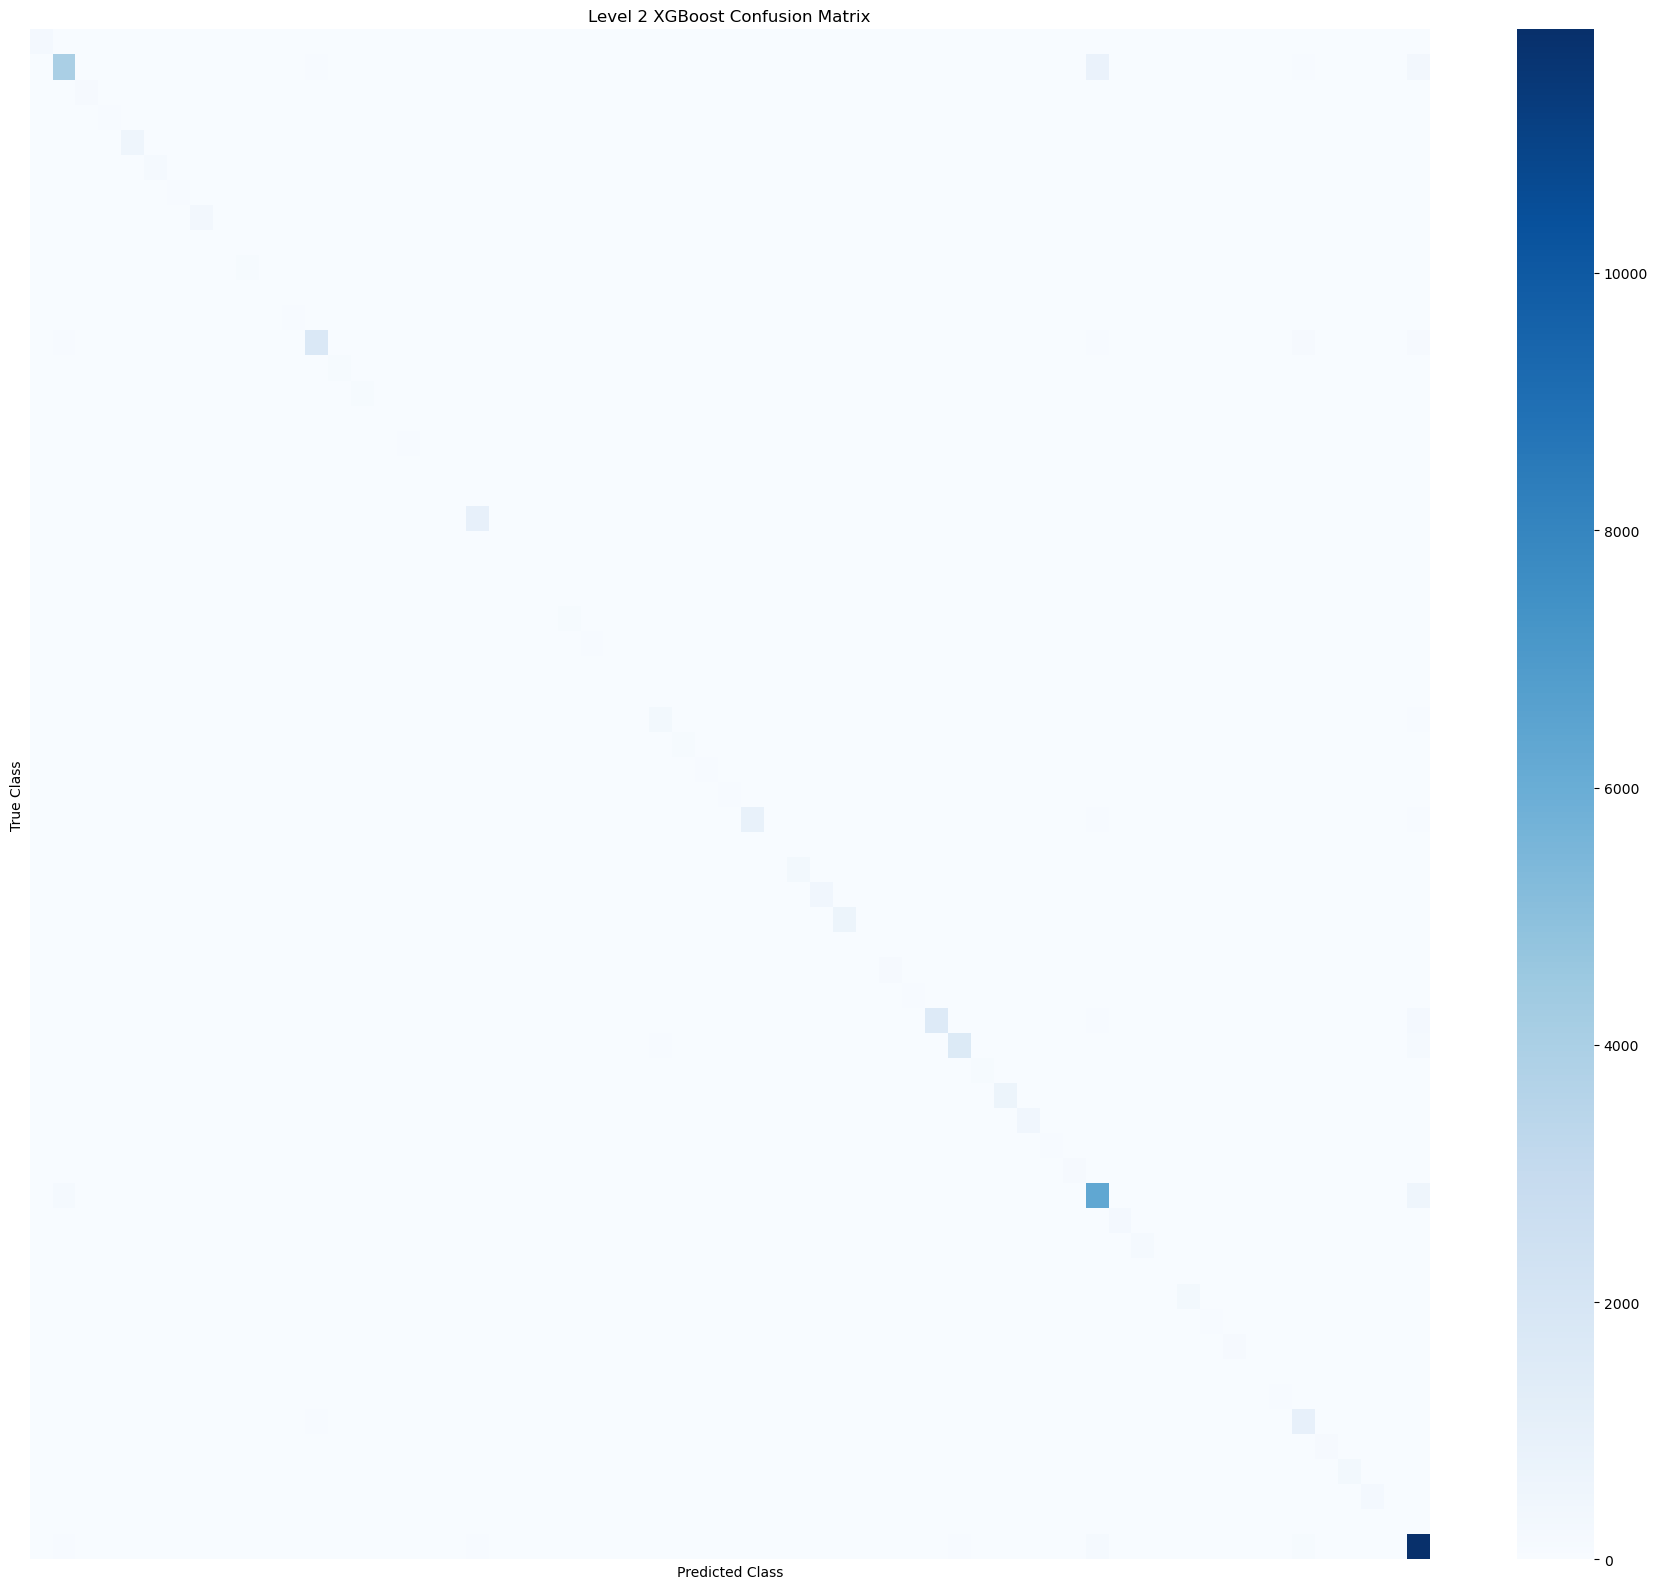

In [3]:
plt.figure(figsize=(18,16))

sns.heatmap(
    cm,
    cmap="Blues",
    cbar=True,
    xticklabels=False,
    yticklabels=False
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Level 2 XGBoost Confusion Matrix")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "Level2_CM_XGBoost.png",
    dpi=300
)

plt.savefig(
    FIGURES_DIR / "Level2_CM_XGBoost.pdf"
)

plt.show()

In [4]:
# ============================================================
# Create ROC-AUC comparison figure in a fresh lightweight session
# No model loading, no prediction matrices, no interactive display
# ============================================================

from pathlib import Path

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ROC_TABLE = (
    TABLES_DIR /
    "Level2_ROC_AUC_Comparison_PairDisjoint.csv"
)

OUTPUT_PNG = (
    FIGURES_DIR /
    "Level2_ROC_AUC_Comparison_PairDisjoint.png"
)

# ------------------------------------------------------------
# Load only the small saved results table
# ------------------------------------------------------------

roc_df = pd.read_csv(ROC_TABLE)

required_columns = [
    "Model",
    "ROC-AUC Macro OvR",
    "ROC-AUC Weighted OvR",
    "ROC-AUC Micro OvR"
]

missing_columns = [
    column
    for column in required_columns
    if column not in roc_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

plot_df = (
    roc_df[
        ["Model", "ROC-AUC Micro OvR"]
    ]
    .sort_values(
        "ROC-AUC Micro OvR",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Create figure without displaying it
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.5, 5.5),
    dpi=150
)

bars = ax.bar(
    plot_df["Model"],
    plot_df["ROC-AUC Micro OvR"],
    width=0.62
)

minimum_value = float(
    plot_df["ROC-AUC Micro OvR"].min()
)

ax.set_ylim(
    max(0.9900, minimum_value - 0.0015),
    1.0002
)

ax.set_xlabel(
    "Model",
    fontsize=11
)

ax.set_ylabel(
    "Micro-average ROC–AUC",
    fontsize=11
)

ax.set_title(
    "Level 2 Model Comparison on the Pair-Disjoint Test Set",
    fontsize=12,
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.25
)

for bar, value in zip(
    bars,
    plot_df["ROC-AUC Micro OvR"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.00005,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

fig.tight_layout()

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("=" * 70)
print("ROC-AUC FIGURE CREATED")
print("=" * 70)
print(plot_df.to_string(index=False))
print("\nSaved file:", OUTPUT_PNG)
print("File exists:", OUTPUT_PNG.exists())

if OUTPUT_PNG.exists():
    print(
        "File size:",
        f"{OUTPUT_PNG.stat().st_size / 1024:.1f} KB"
    )

ROC-AUC FIGURE CREATED
        Model  ROC-AUC Micro OvR
      XGBoost             0.9986
Random Forest             0.9985
 SGD Logistic             0.9981

Saved file: C:\Users\user\Desktop\drug drug\drug2\results_level2_pair_disjoint\figures\Level2_ROC_AUC_Comparison_PairDisjoint.png
File exists: True
File size: 122.7 KB


In [5]:
cm_norm = cm.astype(float)
cm_norm /= cm_norm.sum(axis=1, keepdims=True)

cm_norm = np.nan_to_num(cm_norm)

plt.figure(figsize=(18,16))

sns.heatmap(
    cm_norm,
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar=True,
    xticklabels=False,
    yticklabels=False
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Normalized Level 2 XGBoost Confusion Matrix")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "Level2_CM_Normalized_XGBoost.png",
    dpi=300
)

plt.savefig(
    FIGURES_DIR / "Level2_CM_Normalized_XGBoost.pdf"
)

plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_24592\159968419.py:33: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [6]:
from pathlib import Path

BASE_DIR = Path.cwd()
RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

files_to_check = [
    FIGURES_DIR / "Level2_CM_XGBoost.png",
    FIGURES_DIR / "Level2_CM_XGBoost.pdf",
    FIGURES_DIR / "Level2_CM_Normalized_XGBoost.png",
    FIGURES_DIR / "Level2_CM_Normalized_XGBoost.pdf",
    TABLES_DIR / "Level2_XGBoost_ConfusionMatrix.csv"
]

print("=" * 75)
print("CONFUSION MATRIX FILE CHECK")
print("=" * 75)

for file_path in files_to_check:
    print(
        f"{file_path.name:<45} "
        f"{'✓ Found' if file_path.exists() else '✗ Missing'}"
    )

CONFUSION MATRIX FILE CHECK
Level2_CM_XGBoost.png                         ✓ Found
Level2_CM_XGBoost.pdf                         ✓ Found
Level2_CM_Normalized_XGBoost.png              ✓ Found
Level2_CM_Normalized_XGBoost.pdf              ✓ Found
Level2_XGBoost_ConfusionMatrix.csv            ✓ Found


In [7]:
# ============================================================
# Cell 1 — Prepare Level 2 Y-randomization
# Pair-disjoint split
# ============================================================

from pathlib import Path
import gc
import joblib
import numpy as np
import pandas as pd
from scipy import sparse

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
MODELS_DIR = RESULTS_DIR / "models"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
YRAND_DIR = RESULTS_DIR / "y_randomization"

for folder in [
    RESULTS_DIR,
    MODELS_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    YRAND_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Load sparse Morgan matrices
X_train = sparse.load_npz(
    MODELS_DIR / "X_train_PairDisjoint_sparse.npz"
)

X_test = sparse.load_npz(
    MODELS_DIR / "X_test_PairDisjoint_sparse.npz"
)

# Load original labels
y_train = joblib.load(
    MODELS_DIR / "y_train_PairDisjoint.pkl"
)

y_test = joblib.load(
    MODELS_DIR / "y_test_PairDisjoint.pkl"
)

le_level2 = joblib.load(
    MODELS_DIR / "Level2_LabelEncoder.pkl"
)

# File that will accumulate completed runs
YRAND_RESULTS_FILE = (
    YRAND_DIR /
    "Level2_YRandomization_Runs.csv"
)

print("=" * 75)
print("LEVEL 2 Y-RANDOMIZATION SETUP")
print("=" * 75)
print("X_train shape :", X_train.shape)
print("X_test shape  :", X_test.shape)
print("Train labels  :", len(y_train))
print("Test labels   :", len(y_test))
print("Classes       :", len(le_level2.classes_))
print("Results file  :", YRAND_RESULTS_FILE)
print("=" * 75)

assert X_train.shape[0] == len(y_train)
assert X_test.shape[0] == len(y_test)
assert len(np.unique(y_train)) == len(le_level2.classes_)

LEVEL 2 Y-RANDOMIZATION SETUP
X_train shape : (176339, 4096)
X_test shape  : (44086, 4096)
Train labels  : 176339
Test labels   : 44086
Classes       : 61
Results file  : C:\Users\user\Desktop\drug drug\drug2\results_level2_pair_disjoint\y_randomization\Level2_YRandomization_Runs.csv


In [8]:
# ============================================================
# Cell 2 — Original XGBoost performance
# ============================================================

ORIGINAL_RESULTS = {
    "Accuracy": 0.871161,
    "Balanced Accuracy": 0.908721,
    "Macro Precision": 0.918064,
    "Macro Recall": 0.908721,
    "Macro F1": 0.911494,
    "Weighted F1": 0.870007,
    "MCC": 0.850710,
    "Top-3 Accuracy": 0.986753
}

original_results_df = pd.DataFrame(
    {
        "Metric": list(ORIGINAL_RESULTS.keys()),
        "Original XGBoost": list(ORIGINAL_RESULTS.values())
    }
)

display(original_results_df)

original_results_df.to_csv(
    TABLES_DIR /
    "Level2_Original_XGBoost_Performance_PairDisjoint.csv",
    index=False
)

,Metric,Original XGBoost
0,Accuracy,0.871161
1,Balanced Accuracy,0.908721
2,Macro Precision,0.918064
3,Macro Recall,0.908721
4,Macro F1,0.911494
5,Weighted F1,0.870007
6,MCC,0.850710
7,Top-3 Accuracy,0.986753


In [9]:
# ============================================================
# Cell 3 — Resume-safe Level 2 Y-randomization
# Same XGBoost hyperparameters as the original model
# ============================================================

import time
import gc
import numpy as np
import pandas as pd

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    top_k_accuracy_score,
    log_loss
)

N_RUNS = 20
BASE_RANDOM_SEED = 1000
N_CLASSES = len(le_level2.classes_)

# ------------------------------------------------------------
# Load previously completed runs, if any
# ------------------------------------------------------------

if YRAND_RESULTS_FILE.exists():

    yrand_results_df = pd.read_csv(
        YRAND_RESULTS_FILE
    )

    completed_runs = set(
        yrand_results_df["Run"].astype(int)
    )

    print(
        f"Previously completed runs: "
        f"{sorted(completed_runs)}"
    )

else:

    yrand_results_df = pd.DataFrame()

    completed_runs = set()

    print("No previous Y-randomization runs found.")

# ------------------------------------------------------------
# Run shuffled-label models sequentially
# ------------------------------------------------------------

for run_number in range(1, N_RUNS + 1):

    if run_number in completed_runs:
        print(
            f"Run {run_number:02d}/{N_RUNS}: "
            "already completed — skipped."
        )
        continue

    run_seed = BASE_RANDOM_SEED + run_number

    print("\n" + "=" * 75)
    print(
        f"Y-RANDOMIZATION RUN "
        f"{run_number:02d}/{N_RUNS}"
    )
    print("=" * 75)
    print("Random seed:", run_seed)

    start_time = time.time()

    # Shuffle training labels only
    rng = np.random.default_rng(run_seed)

    y_train_randomized = rng.permutation(
        y_train
    )

    # Confirm class counts are preserved
    assert np.array_equal(
        np.bincount(
            y_train_randomized,
            minlength=N_CLASSES
        ),
        np.bincount(
            y_train,
            minlength=N_CLASSES
        )
    )

    randomized_model = XGBClassifier(
        objective="multi:softprob",
        num_class=N_CLASSES,
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=run_seed,
        n_jobs=-1
    )

    # Train using shuffled training labels
    randomized_model.fit(
        X_train,
        y_train_randomized
    )

    # Evaluate against untouched true test labels
    random_pred = randomized_model.predict(
        X_test
    )

    random_prob = randomized_model.predict_proba(
        X_test
    )

    elapsed_seconds = (
        time.time() - start_time
    )

    run_result = {
        "Run": run_number,
        "Random_Seed": run_seed,

        "Accuracy": accuracy_score(
            y_test,
            random_pred
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_test,
            random_pred
        ),

        "Macro_Precision": precision_score(
            y_test,
            random_pred,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y_test,
            random_pred,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_test,
            random_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y_test,
            random_pred,
            average="weighted",
            zero_division=0
        ),

        "MCC": matthews_corrcoef(
            y_test,
            random_pred
        ),

        "Top3_Accuracy": top_k_accuracy_score(
            y_test,
            random_prob,
            k=3,
            labels=np.arange(N_CLASSES)
        ),

        "Multiclass_Log_Loss": log_loss(
            y_test,
            random_prob,
            labels=np.arange(N_CLASSES)
        ),

        "Elapsed_Seconds": elapsed_seconds,
        "Elapsed_Minutes": elapsed_seconds / 60
    }

    # Append and save immediately
    yrand_results_df = pd.concat(
        [
            yrand_results_df,
            pd.DataFrame([run_result])
        ],
        ignore_index=True
    )

    yrand_results_df = (
        yrand_results_df
        .drop_duplicates(
            subset=["Run"],
            keep="last"
        )
        .sort_values("Run")
        .reset_index(drop=True)
    )

    yrand_results_df.to_csv(
        YRAND_RESULTS_FILE,
        index=False
    )

    print("\nRun result:")
    print(
        pd.DataFrame(
            [run_result]
        ).T
    )

    print(
        f"\n✓ Run {run_number:02d} saved."
    )

    # Release memory before next run
    del randomized_model
    del y_train_randomized
    del random_pred
    del random_prob

    gc.collect()

print("\n" + "=" * 75)
print("Y-RANDOMIZATION LOOP FINISHED")
print("=" * 75)
print(
    "Completed runs:",
    len(yrand_results_df)
)

display(yrand_results_df)

No previous Y-randomization runs found.

Y-RANDOMIZATION RUN 01/20
Random seed: 1001

Run result:
                               0
Run                     1.000000
Random_Seed          1001.000000
Accuracy                0.285828
Balanced_Accuracy       0.016367
Macro_Precision         0.010701
Macro_Recall            0.016367
Macro_F1                0.007355
Weighted_F1             0.128090
MCC                    -0.002745
Top3_Accuracy           0.576555
Multiclass_Log_Loss     2.707111
Elapsed_Seconds       469.511518
Elapsed_Minutes         7.825192

✓ Run 01 saved.

Y-RANDOMIZATION RUN 02/20
Random seed: 1002

Run result:
                               0
Run                     2.000000
Random_Seed          1002.000000
Accuracy                0.286372
Balanced_Accuracy       0.016409
Macro_Precision         0.017471
Macro_Recall            0.016409
Macro_F1                0.007399
Weighted_F1             0.128468
MCC                     0.003185
Top3_Accuracy           0.576510
Mu

,Run,Random_Seed,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,MCC,Top3_Accuracy,Multiclass_Log_Loss,Elapsed_Seconds,Elapsed_Minutes
0,1,1001,0.285828,0.016367,0.010701,0.016367,0.007355,0.128090,-0.002745,0.576555,2.707111,469.511518,7.825192
1,2,1002,0.286372,0.016409,0.017471,0.016409,0.007399,0.128468,0.003185,0.576510,2.695429,472.788846,7.879814
2,3,1003,0.285918,0.016369,0.009144,0.016369,0.007340,0.127911,-0.005315,0.576555,2.703147,478.222750,7.970379
3,4,1004,0.286463,0.016407,0.013156,0.016407,0.007377,0.128311,0.003372,0.576373,2.698283,484.138560,8.068976
4,5,1005,0.286032,0.016380,0.008176,0.016380,0.007363,0.128195,-0.001255,0.576782,2.705111,486.457917,8.107632
5,6,1006,0.286486,0.016408,0.009552,0.016408,0.007385,0.128473,0.004175,0.576419,2.702798,473.370951,7.889516
6,7,1007,0.286236,0.016390,0.008544,0.016390,0.007358,0.128164,0.000158,0.576555,2.699119,473.655069,7.894251
7,8,1008,0.286417,0.016403,0.013888,0.016403,0.007372,0.128318,0.003051,0.576532,2.705278,471.614485,7.860241
8,9,1009,0.286486,0.016413,0.027601,0.016413,0.007387,0.128328,0.004259,0.576668,2.697424,472.593071,7.876551
9,10,1010,0.286826,0.016454,0.036316,0.016454,0.007476,0.129151,0.009687,0.576192,2.693683,471.991414,7.866524


In [10]:
# ============================================================
# Cell 4 — Y-randomization summary statistics
# ============================================================

import numpy as np
import pandas as pd

yrand_results_df = pd.read_csv(
    YRAND_RESULTS_FILE
)

metrics_map = {
    "Accuracy": "Accuracy",
    "Balanced Accuracy": "Balanced_Accuracy",
    "Macro Precision": "Macro_Precision",
    "Macro Recall": "Macro_Recall",
    "Macro F1": "Macro_F1",
    "Weighted F1": "Weighted_F1",
    "MCC": "MCC",
    "Top-3 Accuracy": "Top3_Accuracy",
    "Multiclass Log Loss": "Multiclass_Log_Loss"
}

summary_rows = []

for display_name, column_name in metrics_map.items():

    values = yrand_results_df[
        column_name
    ].dropna().to_numpy()

    summary_rows.append({
        "Metric": display_name,

        "Original Model": (
            ORIGINAL_RESULTS.get(
                display_name,
                np.nan
            )
        ),

        "Randomized Mean": np.mean(values),

        "Randomized SD": np.std(
            values,
            ddof=1
        ) if len(values) > 1 else np.nan,

        "Randomized Median": np.median(values),

        "Randomized 2.5%": np.percentile(
            values,
            2.5
        ),

        "Randomized 97.5%": np.percentile(
            values,
            97.5
        ),

        "Number of Runs": len(values)
    })

yrand_summary_df = pd.DataFrame(
    summary_rows
)

numeric_columns = (
    yrand_summary_df.columns
    .difference(
        ["Metric", "Number of Runs"]
    )
)

yrand_summary_df[numeric_columns] = (
    yrand_summary_df[numeric_columns]
    .round(4)
)

display(yrand_summary_df)

yrand_summary_df.to_csv(
    TABLES_DIR /
    "Level2_YRandomization_Summary.csv",
    index=False
)

yrand_summary_df.to_excel(
    TABLES_DIR /
    "Level2_YRandomization_Summary.xlsx",
    index=False
)

print("✓ Y-randomization summary saved.")

,Metric,Original Model,Randomized Mean,Randomized SD,Randomized Median,Randomized 2.5%,Randomized 97.5%,Number of Runs
0,Accuracy,0.8712,0.2864,0.0003,0.2864,0.2859,0.2869,20
1,Balanced Accuracy,0.9087,0.0164,0.0000,0.0164,0.0164,0.0164,20
2,Macro Precision,0.9181,0.0125,0.0073,0.0099,0.0064,0.0322,20
3,Macro Recall,0.9087,0.0164,0.0000,0.0164,0.0164,0.0164,20
4,Macro F1,0.9115,0.0074,0.0000,0.0074,0.0073,0.0075,20
5,Weighted F1,0.8700,0.1283,0.0003,0.1283,0.1279,0.1290,20
6,MCC,0.8507,0.0023,0.0040,0.0028,-0.0044,0.0101,20
7,Top-3 Accuracy,0.9868,0.5765,0.0002,0.5765,0.5762,0.5768,20
8,Multiclass Log Loss,NaN,2.7010,0.0036,2.7013,2.6945,2.7068,20


✓ Y-randomization summary saved.


In [11]:
# ============================================================
# Cell 5 — Empirical significance of Y-randomization
# ============================================================

metric_pairs = {
    "Accuracy": (
        ORIGINAL_RESULTS["Accuracy"],
        "Accuracy",
        "higher"
    ),

    "Balanced Accuracy": (
        ORIGINAL_RESULTS["Balanced Accuracy"],
        "Balanced_Accuracy",
        "higher"
    ),

    "Macro F1": (
        ORIGINAL_RESULTS["Macro F1"],
        "Macro_F1",
        "higher"
    ),

    "Weighted F1": (
        ORIGINAL_RESULTS["Weighted F1"],
        "Weighted_F1",
        "higher"
    ),

    "MCC": (
        ORIGINAL_RESULTS["MCC"],
        "MCC",
        "higher"
    ),

    "Top-3 Accuracy": (
        ORIGINAL_RESULTS["Top-3 Accuracy"],
        "Top3_Accuracy",
        "higher"
    )
}

empirical_rows = []

n_runs = len(
    yrand_results_df
)

for metric_name, (
    original_value,
    random_column,
    direction
) in metric_pairs.items():

    random_values = (
        yrand_results_df[
            random_column
        ]
        .dropna()
        .to_numpy()
    )

    if direction == "higher":

        extreme_count = np.sum(
            random_values >= original_value
        )

    else:

        extreme_count = np.sum(
            random_values <= original_value
        )

    empirical_p = (
        extreme_count + 1
    ) / (
        len(random_values) + 1
    )

    empirical_rows.append({
        "Metric": metric_name,
        "Original Value": original_value,
        "Randomized Mean": random_values.mean(),
        "Randomized Maximum": random_values.max(),
        "Randomized Minimum": random_values.min(),
        "Extreme Random Runs": int(extreme_count),
        "Empirical p-value": empirical_p,
        "Number of Runs": len(random_values)
    })

empirical_df = pd.DataFrame(
    empirical_rows
)

numeric_columns = empirical_df.columns.difference(
    [
        "Metric",
        "Extreme Random Runs",
        "Number of Runs"
    ]
)

empirical_df[numeric_columns] = (
    empirical_df[numeric_columns]
    .round(4)
)

display(empirical_df)

empirical_df.to_csv(
    TABLES_DIR /
    "Level2_YRandomization_Empirical_Test.csv",
    index=False
)

print("✓ Empirical Y-randomization test saved.")

,Metric,Original Value,Randomized Mean,Randomized Maximum,Randomized Minimum,Extreme Random Runs,Empirical p-value,Number of Runs
0,Accuracy,0.8712,0.2864,0.2869,0.2858,0,0.0476,20
1,Balanced Accuracy,0.9087,0.0164,0.0165,0.0164,0,0.0476,20
2,Macro F1,0.9115,0.0074,0.0075,0.0073,0,0.0476,20
3,Weighted F1,0.8700,0.1283,0.1292,0.1279,0,0.0476,20
4,MCC,0.8507,0.0023,0.0105,-0.0053,0,0.0476,20
5,Top-3 Accuracy,0.9868,0.5765,0.5768,0.5762,0,0.0476,20


✓ Empirical Y-randomization test saved.


In [12]:
# ============================================================
# Level 2 Y-randomization figure
# Original XGBoost versus 20 randomized-label models
# ============================================================

from pathlib import Path

import matplotlib
matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Directories
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
YRAND_DIR = RESULTS_DIR / "y_randomization"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in [
    RESULTS_DIR,
    YRAND_DIR,
    TABLES_DIR,
    FIGURES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Input and output files
# ------------------------------------------------------------

YRAND_RESULTS_FILE = (
    YRAND_DIR /
    "Level2_YRandomization_Runs.csv"
)

OUTPUT_PNG = (
    FIGURES_DIR /
    "Level2_YRandomization_Comparison.png"
)

OUTPUT_PDF = (
    FIGURES_DIR /
    "Level2_YRandomization_Comparison.pdf"
)

PLOT_DATA_FILE = (
    TABLES_DIR /
    "Level2_YRandomization_Plot_Data.csv"
)

# ------------------------------------------------------------
# Load the 20 randomized runs
# ------------------------------------------------------------

yrand_df = pd.read_csv(
    YRAND_RESULTS_FILE
)

required_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "Macro_F1",
    "MCC"
]

missing_columns = [
    column
    for column in required_columns
    if column not in yrand_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing Y-randomization columns: {missing_columns}"
    )

print("Number of randomized runs:", len(yrand_df))

if len(yrand_df) != 20:
    print(
        "Warning: the expected number of randomized runs is 20, "
        f"but {len(yrand_df)} runs were found."
    )

# ------------------------------------------------------------
# Original pair-disjoint XGBoost results
# ------------------------------------------------------------

original_values = {
    "Accuracy": 0.871161,
    "Balanced Accuracy": 0.908721,
    "Macro F1": 0.911494,
    "MCC": 0.850710
}

metric_columns = {
    "Accuracy": "Accuracy",
    "Balanced Accuracy": "Balanced_Accuracy",
    "Macro F1": "Macro_F1",
    "MCC": "MCC"
}

metric_names = list(metric_columns.keys())

randomized_values = [
    yrand_df[metric_columns[metric]].dropna().to_numpy()
    for metric in metric_names
]

original_array = np.array(
    [original_values[metric] for metric in metric_names],
    dtype=float
)

# ------------------------------------------------------------
# Save numerical data used in the figure
# ------------------------------------------------------------

plot_data_rows = []

for metric in metric_names:

    random_column = metric_columns[metric]
    random_values = yrand_df[random_column].dropna()

    plot_data_rows.append({
        "Metric": metric,
        "Original_Model": original_values[metric],
        "Randomized_Mean": random_values.mean(),
        "Randomized_SD": random_values.std(ddof=1),
        "Randomized_Minimum": random_values.min(),
        "Randomized_Maximum": random_values.max(),
        "Randomized_Median": random_values.median(),
        "Randomized_2.5_Percentile": random_values.quantile(0.025),
        "Randomized_97.5_Percentile": random_values.quantile(0.975),
        "Number_of_Runs": len(random_values)
    })

plot_data_df = pd.DataFrame(
    plot_data_rows
)

plot_data_df.to_csv(
    PLOT_DATA_FILE,
    index=False
)

display(
    plot_data_df.round(4)
)

# ------------------------------------------------------------
# Create one lightweight boxplot
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6.5),
    dpi=120
)

positions = np.arange(
    1,
    len(metric_names) + 1
)

boxplot = ax.boxplot(
    randomized_values,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showmeans=True,
    meanline=False,
    showfliers=True
)

# Original model values
ax.scatter(
    positions,
    original_array,
    marker="*",
    s=150,
    zorder=5,
    label="Original XGBoost model"
)

# Add original values above the stars
for position, value in zip(
    positions,
    original_array
):
    ax.text(
        position,
        value + 0.025,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

ax.set_xticks(
    positions
)

ax.set_xticklabels(
    metric_names,
    rotation=15,
    ha="right"
)

ax.set_ylabel(
    "Performance score",
    fontsize=11
)

ax.set_xlabel(
    "Evaluation metric",
    fontsize=11
)

ax.set_title(
    "Level 2 Y-Randomization Validation\n"
    "Original XGBoost Model versus 20 Randomized-Label Models",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylim(
    -0.08,
    1.02
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

ax.grid(
    axis="y",
    alpha=0.25
)

ax.legend(
    loc="center right",
    fontsize=9,
    frameon=True
)

fig.tight_layout()

# ------------------------------------------------------------
# Save without displaying interactively
# ------------------------------------------------------------

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("Y-RANDOMIZATION FIGURE SAVED")
print("=" * 75)

print("PNG exists:", OUTPUT_PNG.exists())
print("PDF exists:", OUTPUT_PDF.exists())
print("Plot-data table exists:", PLOT_DATA_FILE.exists())

if OUTPUT_PNG.exists():
    print(
        "PNG size:",
        f"{OUTPUT_PNG.stat().st_size / 1024:.1f} KB"
    )

print("\nPNG:", OUTPUT_PNG)
print("PDF:", OUTPUT_PDF)
print("Data:", PLOT_DATA_FILE)

Number of randomized runs: 20


,Metric,Original_Model,Randomized_Mean,Randomized_SD,Randomized_Minimum,Randomized_Maximum,Randomized_Median,Randomized_2.5_Percentile,Randomized_97.5_Percentile,Number_of_Runs
0,Accuracy,0.8712,0.2864,0.0003,0.2858,0.2869,0.2864,0.2859,0.2869,20
1,Balanced Accuracy,0.9087,0.0164,0.0000,0.0164,0.0165,0.0164,0.0164,0.0164,20
2,Macro F1,0.9115,0.0074,0.0000,0.0073,0.0075,0.0074,0.0073,0.0075,20
3,MCC,0.8507,0.0023,0.0040,-0.0053,0.0105,0.0028,-0.0044,0.0101,20



Y-RANDOMIZATION FIGURE SAVED
PNG exists: True
PDF exists: True
Plot-data table exists: True
PNG size: 186.8 KB

PNG: C:\Users\user\Desktop\drug drug\drug2\results_level2_pair_disjoint\figures\Level2_YRandomization_Comparison.png
PDF: C:\Users\user\Desktop\drug drug\drug2\results_level2_pair_disjoint\figures\Level2_YRandomization_Comparison.pdf
Data: C:\Users\user\Desktop\drug drug\drug2\results_level2_pair_disjoint\tables\Level2_YRandomization_Plot_Data.csv


In [13]:
# ============================================================
# Majority-class baseline for Level 2
# Pair-disjoint test set
# ============================================================

from pathlib import Path
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    top_k_accuracy_score,
    log_loss
)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
MODELS_DIR = RESULTS_DIR / "models"
TABLES_DIR = RESULTS_DIR / "tables"

for folder in [
    RESULTS_DIR,
    MODELS_DIR,
    TABLES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Load labels and encoder only
# ------------------------------------------------------------

y_train = joblib.load(
    MODELS_DIR / "y_train_PairDisjoint.pkl"
)

y_test = joblib.load(
    MODELS_DIR / "y_test_PairDisjoint.pkl"
)

le_level2 = joblib.load(
    MODELS_DIR / "Level2_LabelEncoder.pkl"
)

n_classes = len(le_level2.classes_)

# ------------------------------------------------------------
# Identify the majority class from TRAINING labels only
# ------------------------------------------------------------

train_class_counts = np.bincount(
    y_train,
    minlength=n_classes
)

majority_class_index = int(
    np.argmax(train_class_counts)
)

majority_class_label = le_level2.inverse_transform(
    [majority_class_index]
)[0]

majority_train_count = int(
    train_class_counts[majority_class_index]
)

majority_train_fraction = (
    majority_train_count / len(y_train)
)

# ------------------------------------------------------------
# Predict the majority class for every test sample
# ------------------------------------------------------------

majority_pred = np.full(
    shape=len(y_test),
    fill_value=majority_class_index,
    dtype=int
)

# ------------------------------------------------------------
# Frequency-based probability baseline
# Uses training class frequencies for every test sample
# ------------------------------------------------------------

train_class_probabilities = (
    train_class_counts / train_class_counts.sum()
)

frequency_prob = np.tile(
    train_class_probabilities,
    (len(y_test), 1)
)

# ------------------------------------------------------------
# Calculate metrics
# ------------------------------------------------------------

majority_results = {
    "Model": "Majority-class baseline",

    "Accuracy": accuracy_score(
        y_test,
        majority_pred
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_test,
        majority_pred
    ),

    "Macro Precision": precision_score(
        y_test,
        majority_pred,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_test,
        majority_pred,
        average="macro",
        zero_division=0
    ),

    "Macro F1": f1_score(
        y_test,
        majority_pred,
        average="macro",
        zero_division=0
    ),

    "Weighted F1": f1_score(
        y_test,
        majority_pred,
        average="weighted",
        zero_division=0
    ),

    "MCC": matthews_corrcoef(
        y_test,
        majority_pred
    ),

    "Top-3 Accuracy": top_k_accuracy_score(
        y_test,
        frequency_prob,
        k=3,
        labels=np.arange(n_classes)
    ),

    "Multiclass Log Loss": log_loss(
        y_test,
        frequency_prob,
        labels=np.arange(n_classes)
    )
}

majority_results_df = pd.DataFrame(
    [majority_results]
)

numeric_columns = majority_results_df.columns.drop(
    "Model"
)

majority_results_df[numeric_columns] = (
    majority_results_df[numeric_columns]
    .round(4)
)

# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("=" * 75)
print("LEVEL 2 MAJORITY BASELINE")
print("=" * 75)

print(f"Majority class index       : {majority_class_index}")
print(f"Majority class label       : {majority_class_label}")
print(f"Training count             : {majority_train_count:,}")
print(f"Training proportion        : {majority_train_fraction:.4f}")
print(f"Number of Level 2 classes  : {n_classes}")

display(majority_results_df)

# ------------------------------------------------------------
# Save baseline outputs
# ------------------------------------------------------------

majority_results_df.to_csv(
    TABLES_DIR /
    "Level2_Majority_Baseline_PairDisjoint.csv",
    index=False
)

joblib.dump(
    majority_pred,
    MODELS_DIR /
    "MajorityBaseline_y_pred_PairDisjoint.pkl",
    compress=3
)

np.save(
    MODELS_DIR /
    "FrequencyBaseline_y_prob_PairDisjoint.npy",
    frequency_prob.astype(np.float32)
)

print("✓ Majority baseline metrics saved.")
print("✓ Majority predictions saved.")
print("✓ Frequency-based scores saved.")

LEVEL 2 MAJORITY BASELINE
Majority class index       : 60
Majority class label       : 113
Training count             : 50,361
Training proportion        : 0.2856
Number of Level 2 classes  : 61


,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,MCC,Top-3 Accuracy,Multiclass Log Loss
0,Majority-class baseline,0.2865,0.0164,0.0047,0.0164,0.0073,0.1276,0.0,0.5771,2.677


✓ Majority baseline metrics saved.
✓ Majority predictions saved.
✓ Frequency-based scores saved.


In [14]:
# ============================================================
# Add majority baseline to the existing model comparison table
# ============================================================

from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd()

RESULTS_DIR = BASE_DIR / "results_level2_pair_disjoint"
TABLES_DIR = RESULTS_DIR / "tables"

comparison_file = (
    TABLES_DIR /
    "Level2_Model_Comparison_PairDisjoint.csv"
)

majority_file = (
    TABLES_DIR /
    "Level2_Majority_Baseline_PairDisjoint.csv"
)

comparison_df = pd.read_csv(
    comparison_file
)

majority_df = pd.read_csv(
    majority_file
)

# Keep only columns common to both tables
common_columns = [
    column
    for column in comparison_df.columns
    if column in majority_df.columns
]

combined_df = pd.concat(
    [
        comparison_df[common_columns],
        majority_df[common_columns]
    ],
    ignore_index=True
)

combined_df = (
    combined_df
    .drop_duplicates(
        subset=["Model"],
        keep="last"
    )
    .sort_values(
        by=["Macro F1", "MCC"],
        ascending=False
    )
    .reset_index(drop=True)
)

display(combined_df)

combined_df.to_csv(
    TABLES_DIR /
    "Level2_Model_Comparison_With_Baseline.csv",
    index=False
)

combined_df.to_excel(
    TABLES_DIR /
    "Level2_Model_Comparison_With_Baseline.xlsx",
    index=False
)

print("✓ Final comparison table with majority baseline saved.")

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,MCC,Top-3 Accuracy,Multiclass Log Loss
0,XGBoost,0.8712,0.9087,0.9181,0.9087,0.9115,0.8700,0.8507,0.9868,0.4868
1,Random Forest,0.8823,0.8406,0.9206,0.8406,0.8740,0.8810,0.8635,0.9900,0.4538
2,SGD Logistic,0.8667,0.7975,0.8947,0.7975,0.8301,0.8642,0.8452,0.9838,0.4182
3,Majority-class baseline,0.2865,0.0164,0.0047,0.0164,0.0073,0.1276,0.0000,0.5771,2.6770


✓ Final comparison table with majority baseline saved.
